# Decision Tree Classification and Regression - Complete ML Lab Tutorial

## Objectives
This notebook provides a complete machine learning workflow:

1. Dataset understanding
2. Detailed Exploratory Data Analysis (EDA)
3. Data visualization
4. Feature analysis
5. Decision Tree Classification
6. Model evaluation
7. Feature importance interpretation
8. Overfitting control
9. Decision Tree Regression

## 1. Import Required Libraries

The following libraries are used:

- **Pandas**: Data loading and manipulation
- **NumPy**: Numerical operations
- **Matplotlib/Seaborn**: Data visualization
- **Scikit-learn**: Machine learning models and evaluation metrics



## 1. Import Required Libraries

The following libraries are used:

- **Pandas**: Data loading and manipulation
- **NumPy**: Numerical operations
- **Matplotlib/Seaborn**: Data visualization
- **Scikit-learn**: Machine learning models and evaluation metrics



In [73]:
# Import data manipulation and numerical operation libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import machine learning models and utilities from scikit-learn
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import specific metrics for model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Ignore warnings to keep the output clean
import warnings
warnings.filterwarnings('ignore')

## 2. Load Dataset

The wine dataset contains chemical properties of wine samples.

Each row represents one wine sample.

In [74]:
# Load the wine dataset from the 'wine.csv' file into a pandas DataFrame
data = pd.read_csv("wine.csv")

# Print the shape of the DataFrame (number of rows, number of columns)
print("Dataset Shape:", data.shape)

# Display the first 5 rows of the DataFrame to inspect the data
data.head()

Dataset Shape: (178, 14)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1



Features include:
- Alcohol concentration
- Acidity
- Magnesium
- Phenols
- Flavanoids
- Proline concentration

The target variable represents the wine class.

## 3. Dataset Information



### This section checks:
- Column names
- Data types
- Missing values

Understanding data quality is important before applying machine learning algorithms.

In [75]:
# Dataset Information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Customer_Segment      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


### Missing Values

In [76]:
print("\nMissing Values in the Dataset:")
print(data.isnull().sum())


Missing Values in the Dataset:
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64


### Statistical Summary

The describe() function provides:

- Mean
- Standard deviation
- Minimum
- Maximum
- Quartiles

This helps identify feature ranges.

In [77]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic_Acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Ash_Alcanity,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Total_Phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoid_Phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
Color_Intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


### Duplicate Record Analysis

In [78]:
print("Duplicated records:", data.duplicated().sum())

Duplicated records: 0


### Target Variable Distribution

A balanced target distribution helps avoid biased classification models.

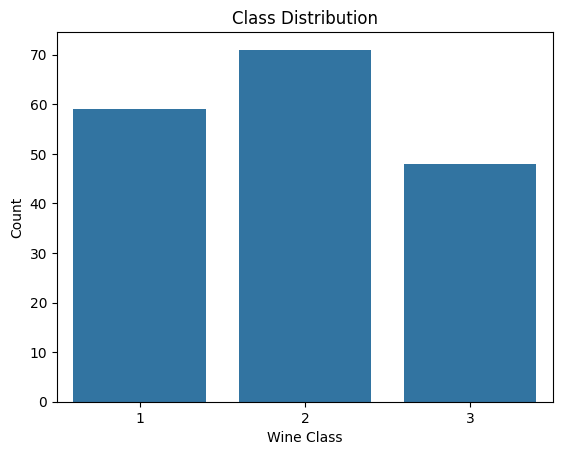

Customer_Segment
2    39.887640
1    33.146067
3    26.966292
Name: proportion, dtype: float64


In [79]:
label = data["Customer_Segment"]
sns.countplot(x=label)

plt.title("Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Count")

plt.show()

print(label.value_counts(normalize=True)*100)


### Feature Distribution Analysis

Histograms show how numerical features are distributed.

Box plots help identify:
- Extreme values
- Skewness
- Possible outliers

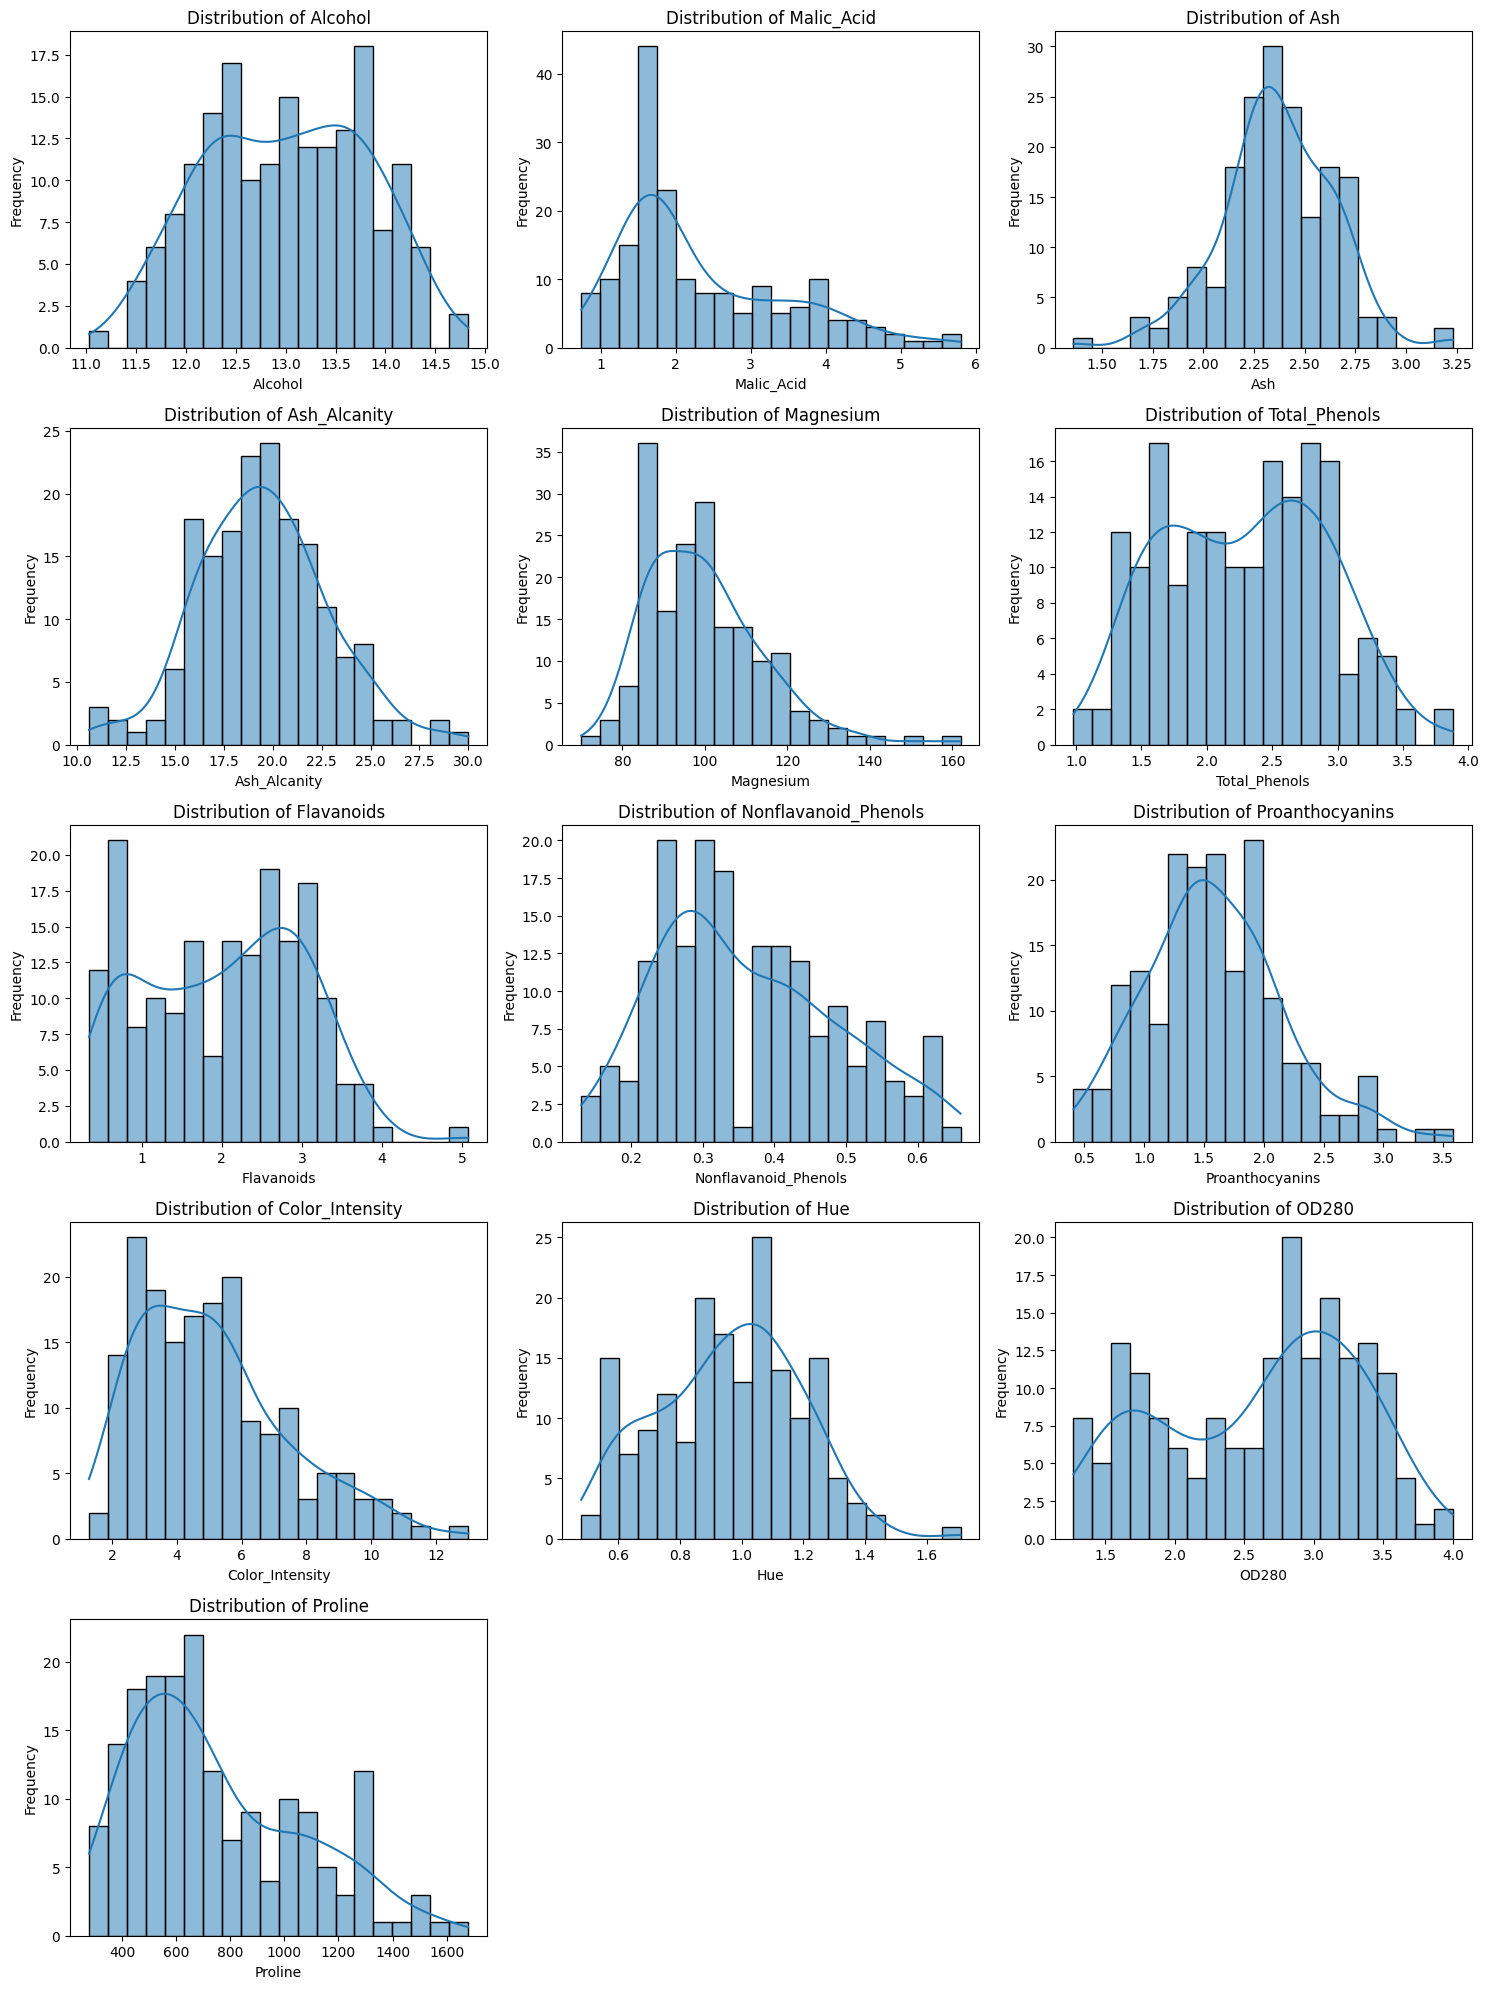

In [80]:
# Define the list of feature columns for analysis
feature_col = [
'Alcohol','Malic_Acid','Ash','Ash_Alcanity','Magnesium',
'Total_Phenols','Flavanoids','Nonflavanoid_Phenols',
'Proanthocyanins','Color_Intensity','Hue','OD280','Proline'
]

# Create a new DataFrame containing only the feature columns
features = data[feature_col]

# Calculate the number of rows needed for a 3-column grid layout
num_features = len(feature_col)
num_cols = 3
num_rows = (num_features + num_cols - 1) // num_cols # Ceiling division to ensure all features are plotted

# Create a figure with a dynamic size based on the number of plots
plt.figure(figsize=(num_cols * 5, num_rows * 4))

# Loop through each feature column to create a histogram with KDE
for i, col in enumerate(feature_col):
    plt.subplot(num_rows, num_cols, i + 1) # Position the subplot in the grid
    sns.histplot(data[col], kde=True, bins=20) # Create a histogram with Kernel Density Estimate
    plt.title(f'Distribution of {col}') # Set subplot title
    plt.xlabel(col) # Set x-axis label
    plt.ylabel('Frequency') # Set y-axis label

# Adjust layout to prevent plot titles and labels from overlapping
plt.tight_layout()
plt.show() # Display the plots

### Feature Outlier Analysis

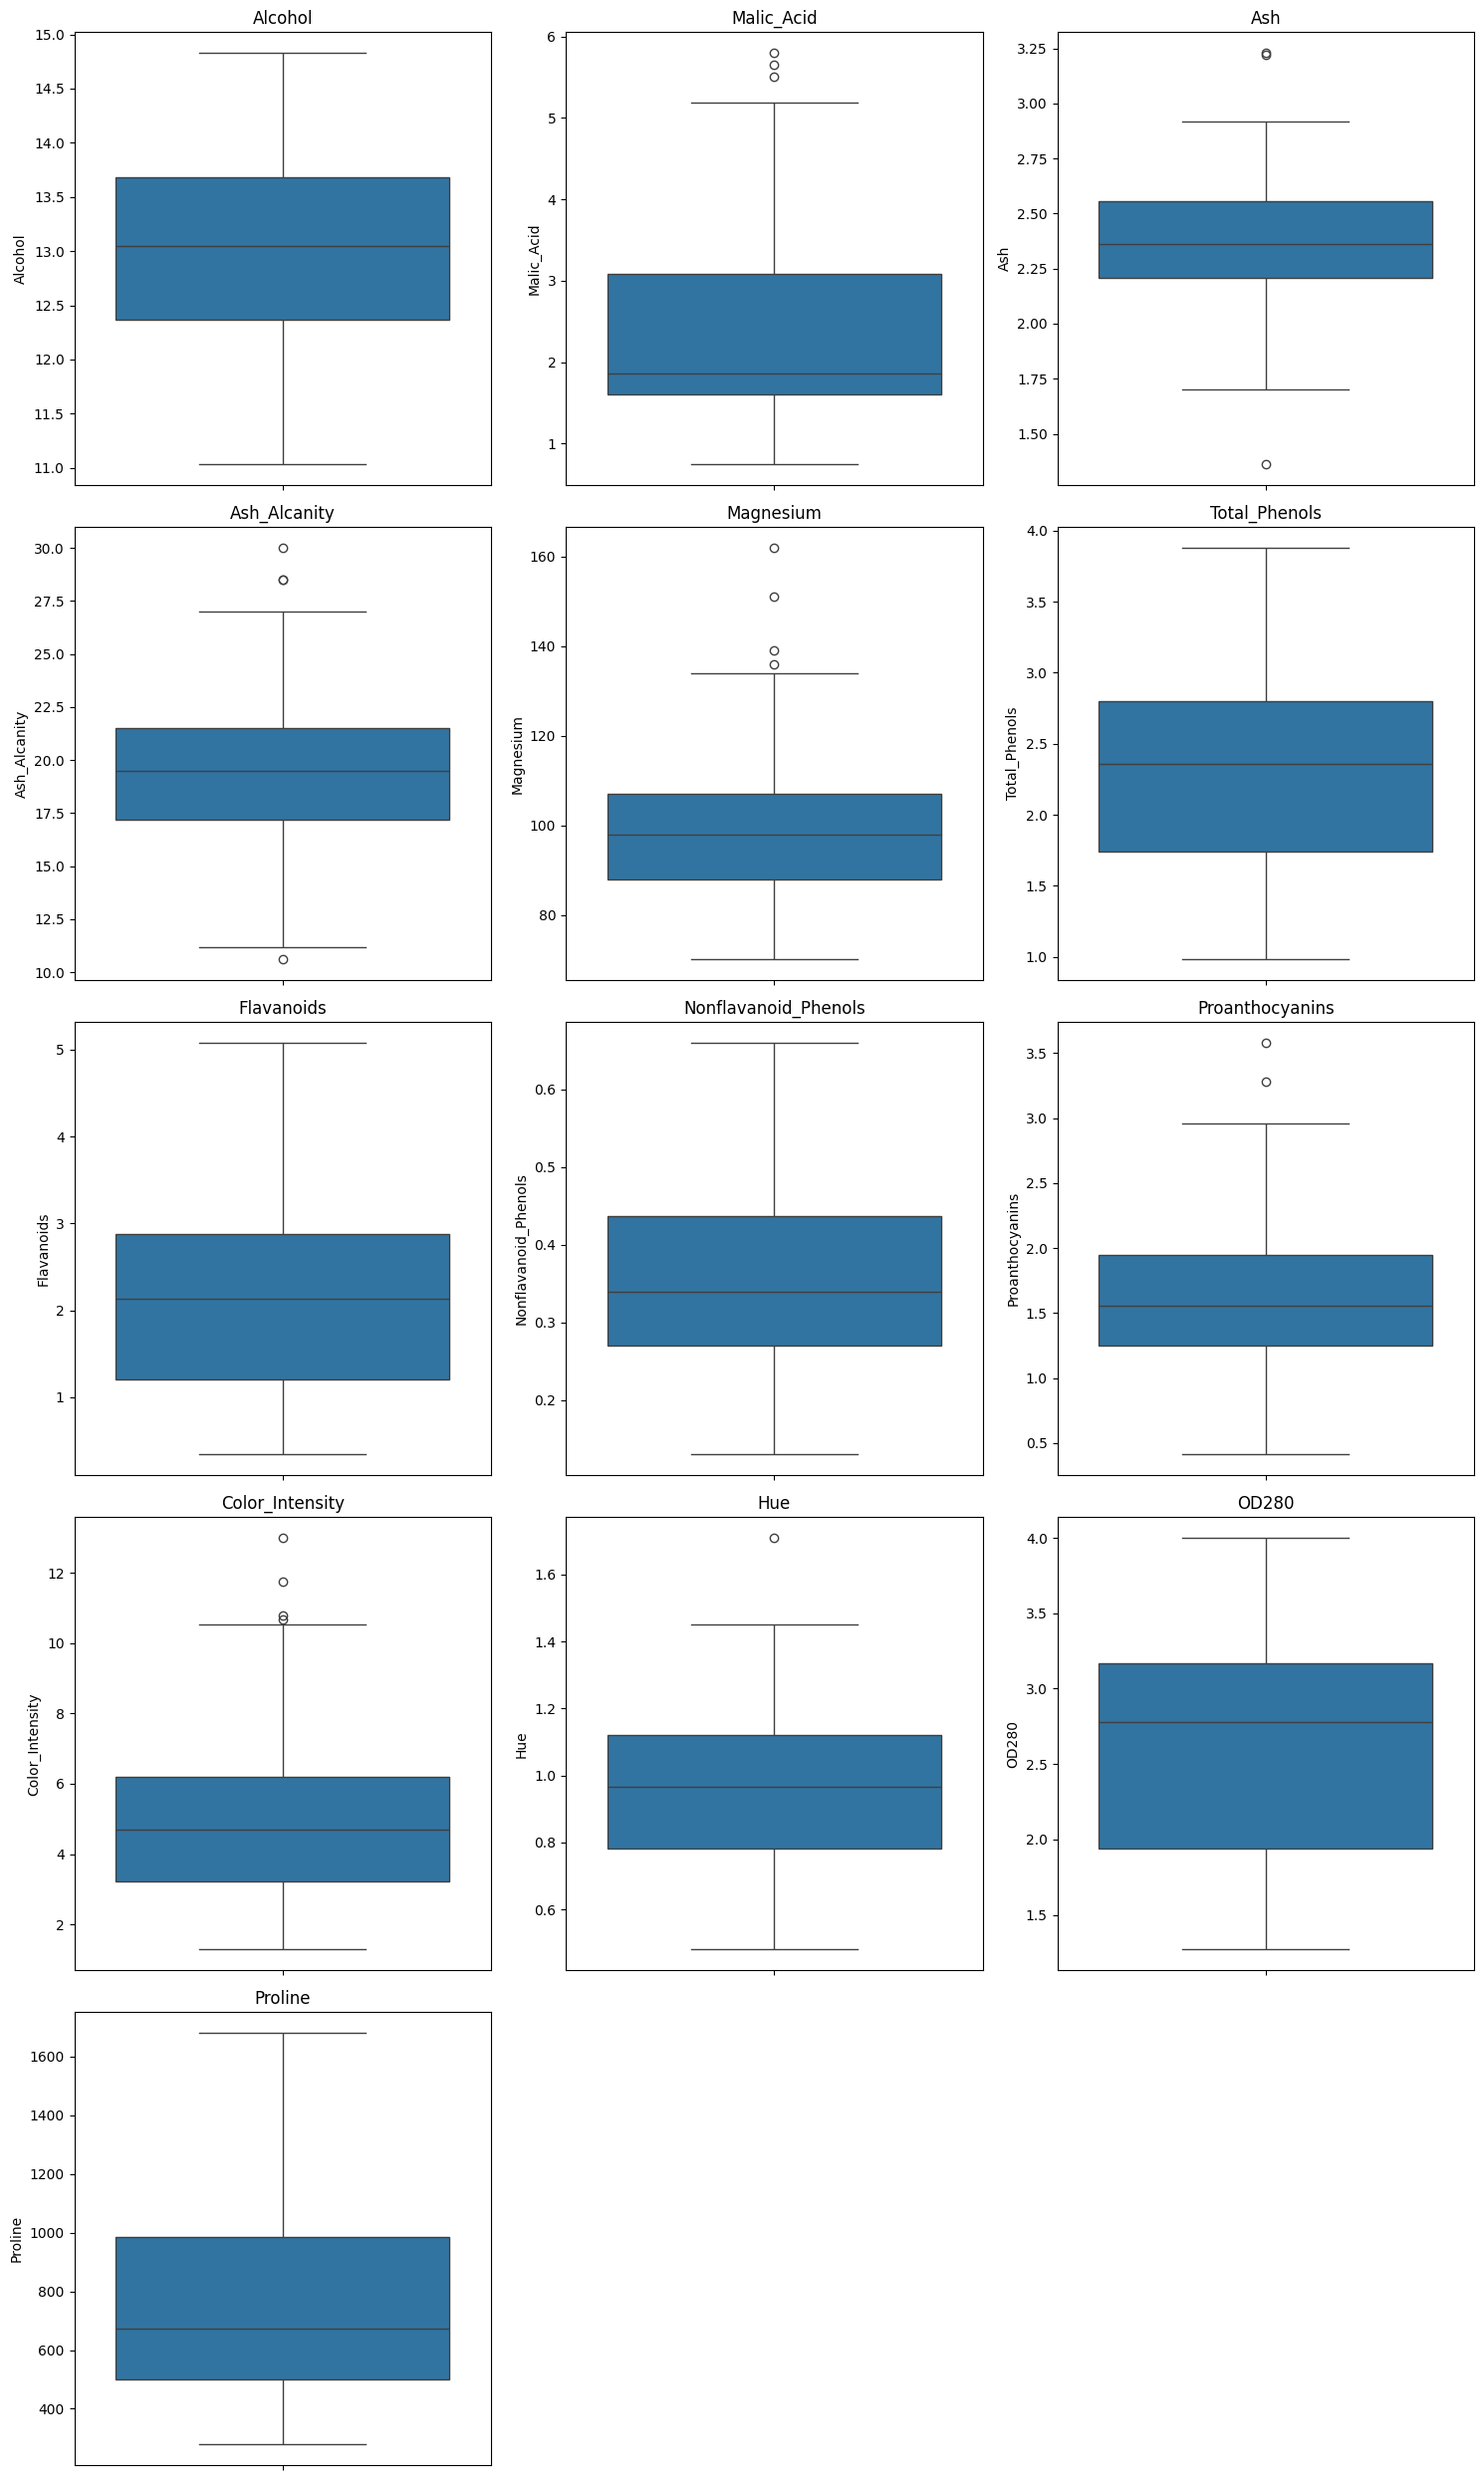

In [81]:
n_cols = 3
n_rows = (len(feature_col) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, features.columns):
    sns.boxplot(y=features[col], ax=ax)
    ax.set_title(col)

# Remove empty subplots
for ax in axes[len(features.columns):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

### Correlation Analysis

Correlation measures linear relationships between features.

High correlation between features may indicate redundant information.

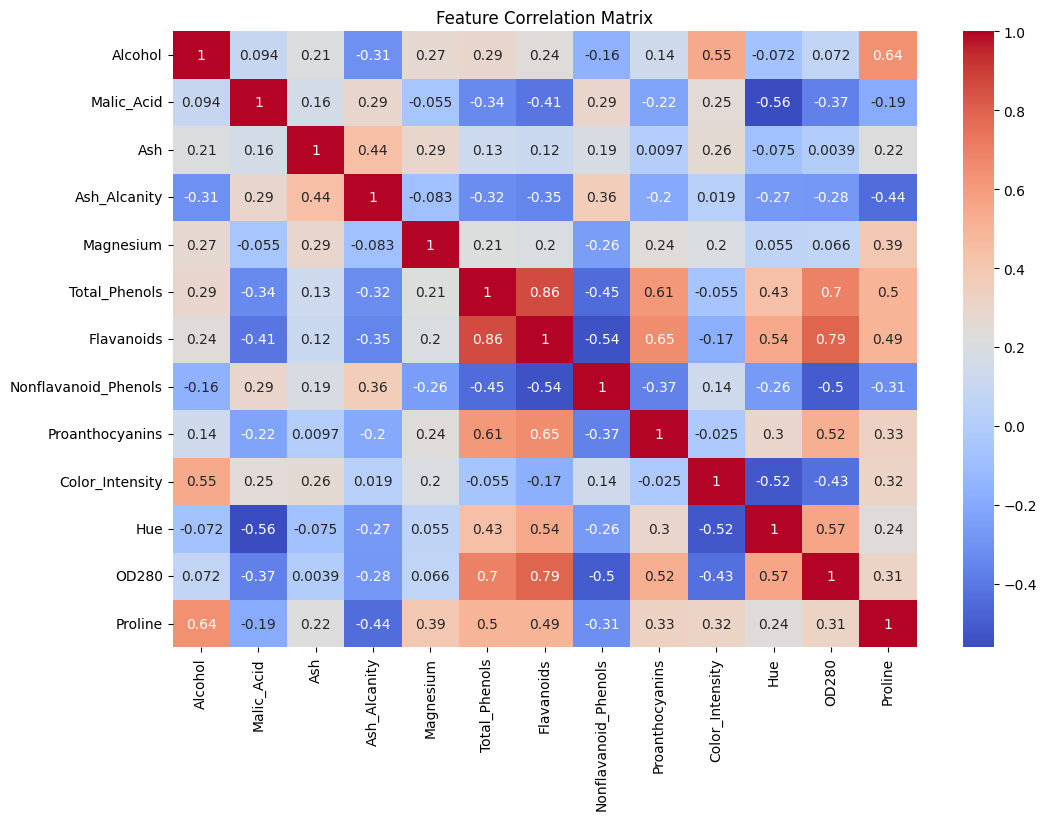

In [82]:
plt.figure(figsize=(12,8))
sns.heatmap(features.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.show()

### Pair Plot Analysis

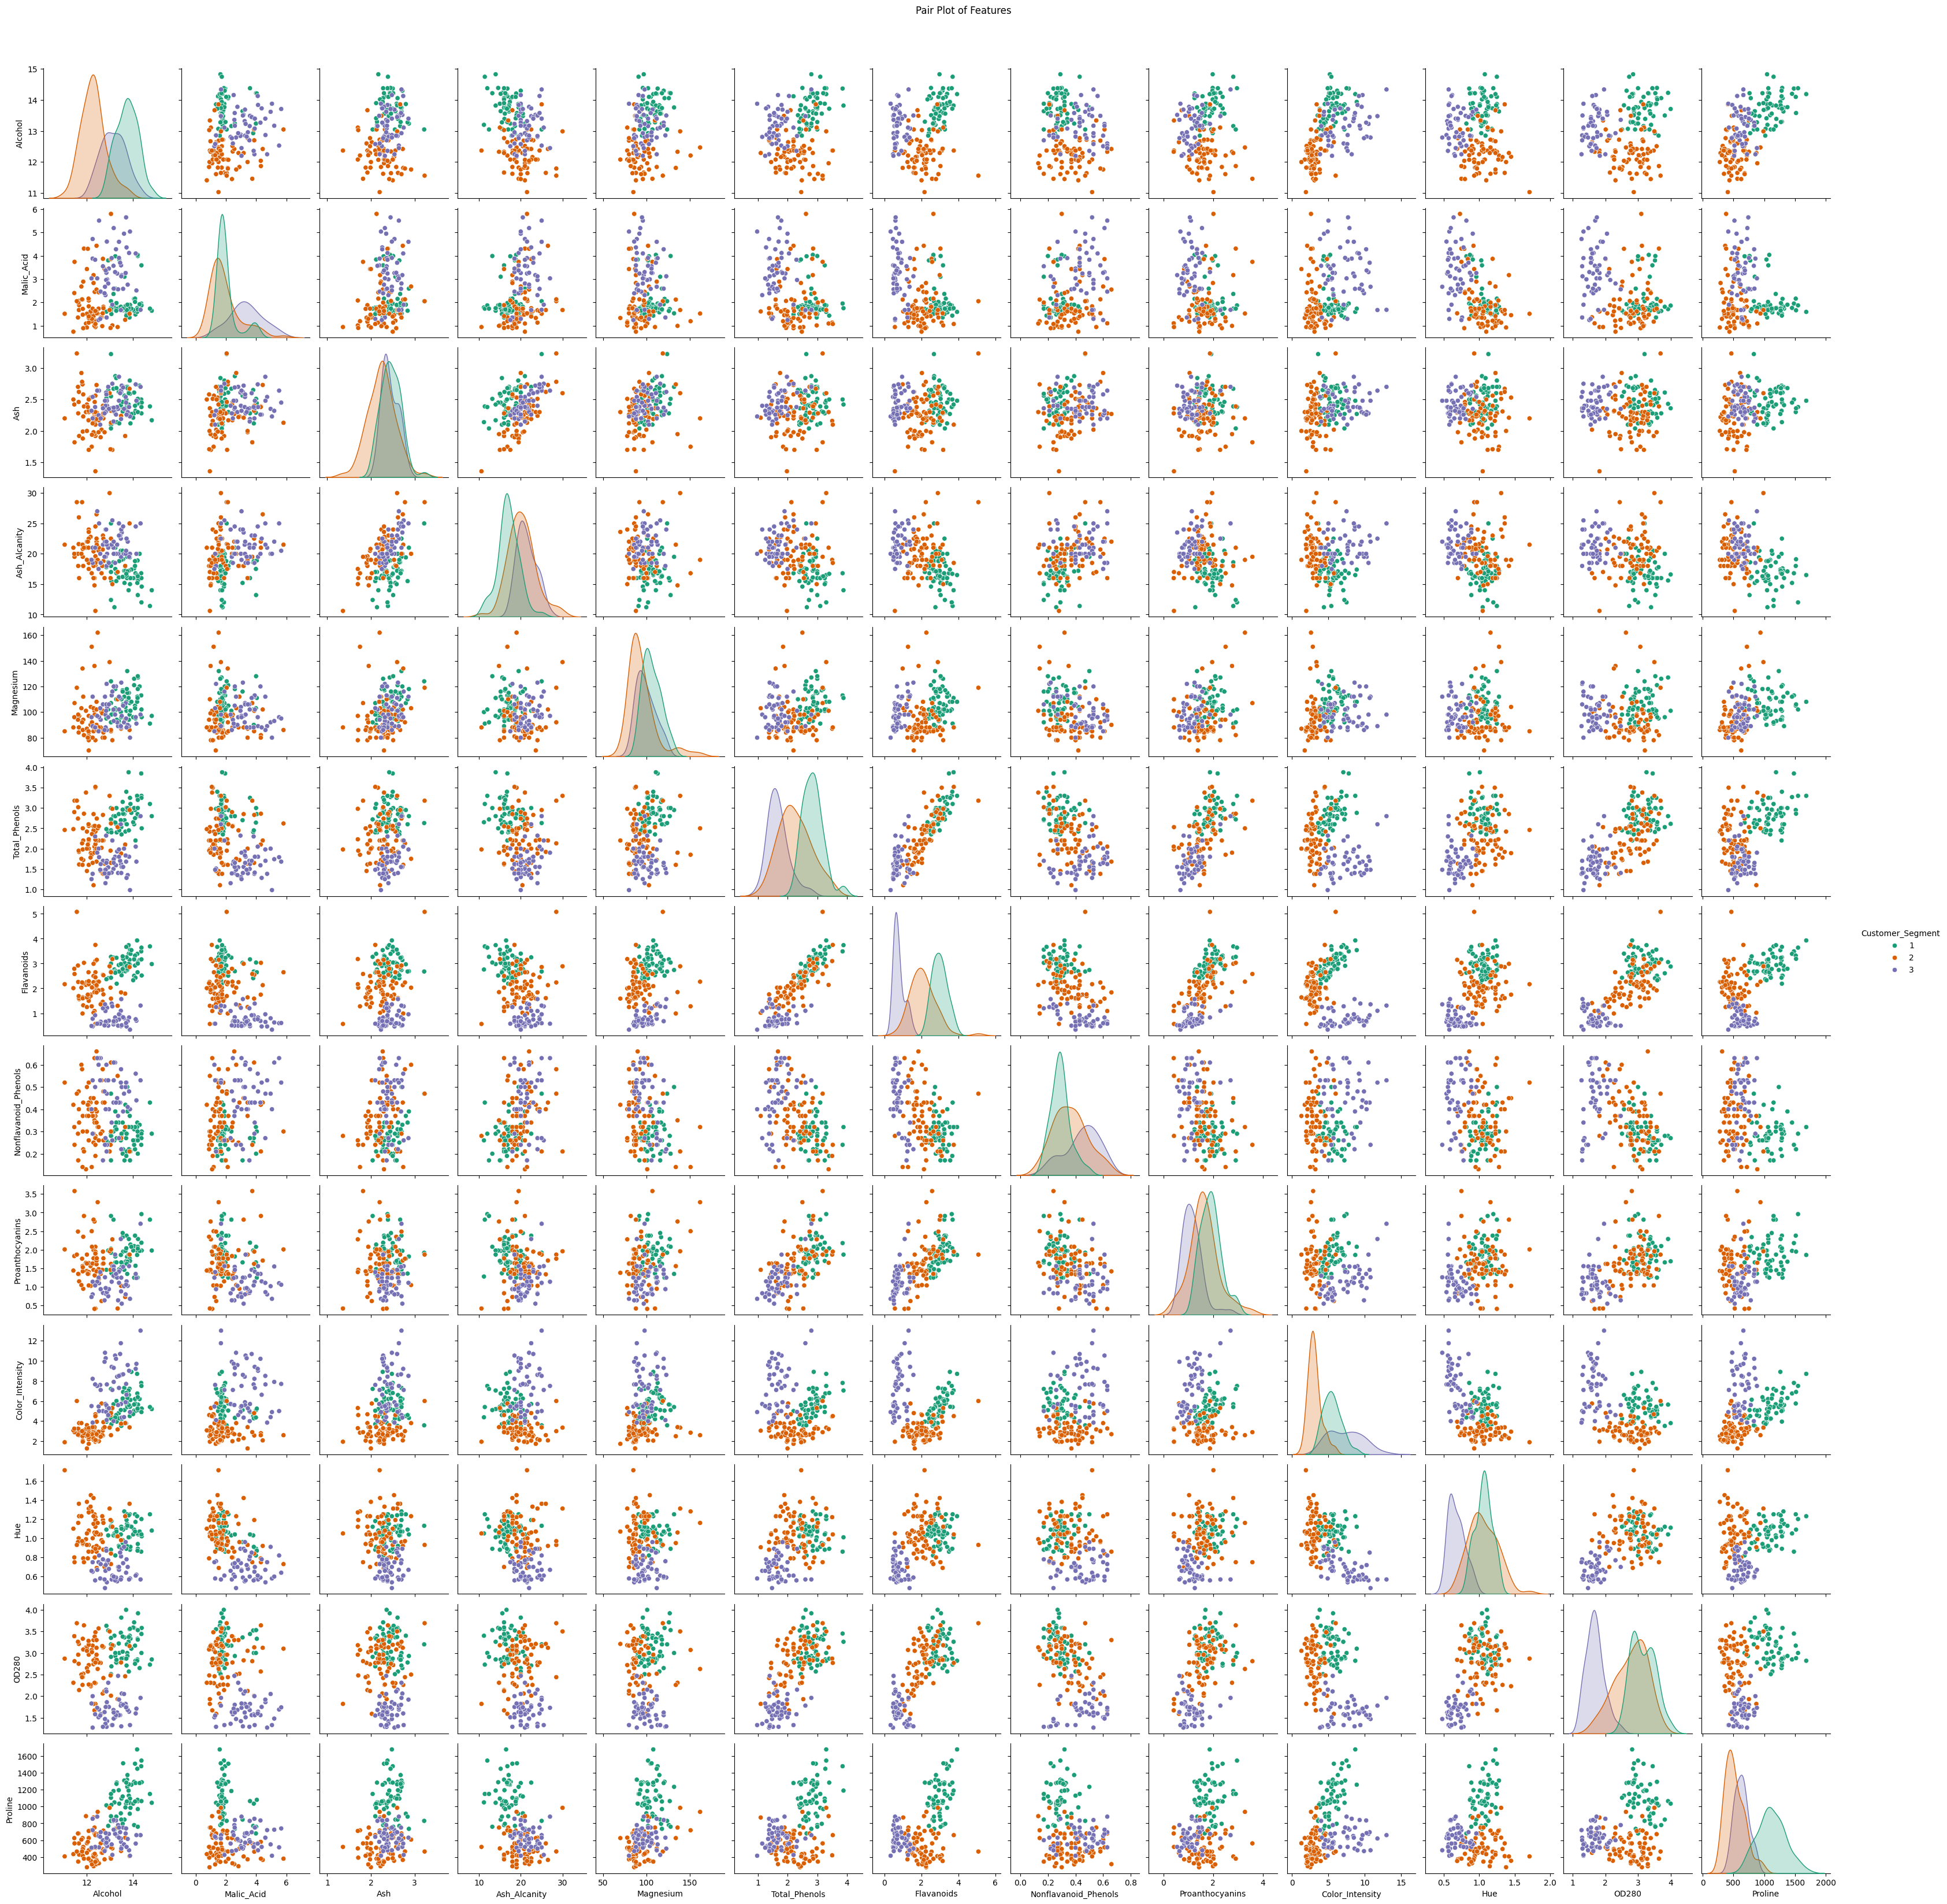

In [83]:
# Generate a pair plot to visualize pairwise relationships between features
# 'hue' is set to 'Customer_Segment' to color points by wine class
sns.pairplot(
    data,
    hue='Customer_Segment',
    palette='Dark2'
)
plt.suptitle('Pair Plot of Features', y=1.02)
plt.show()

### Violine Plot

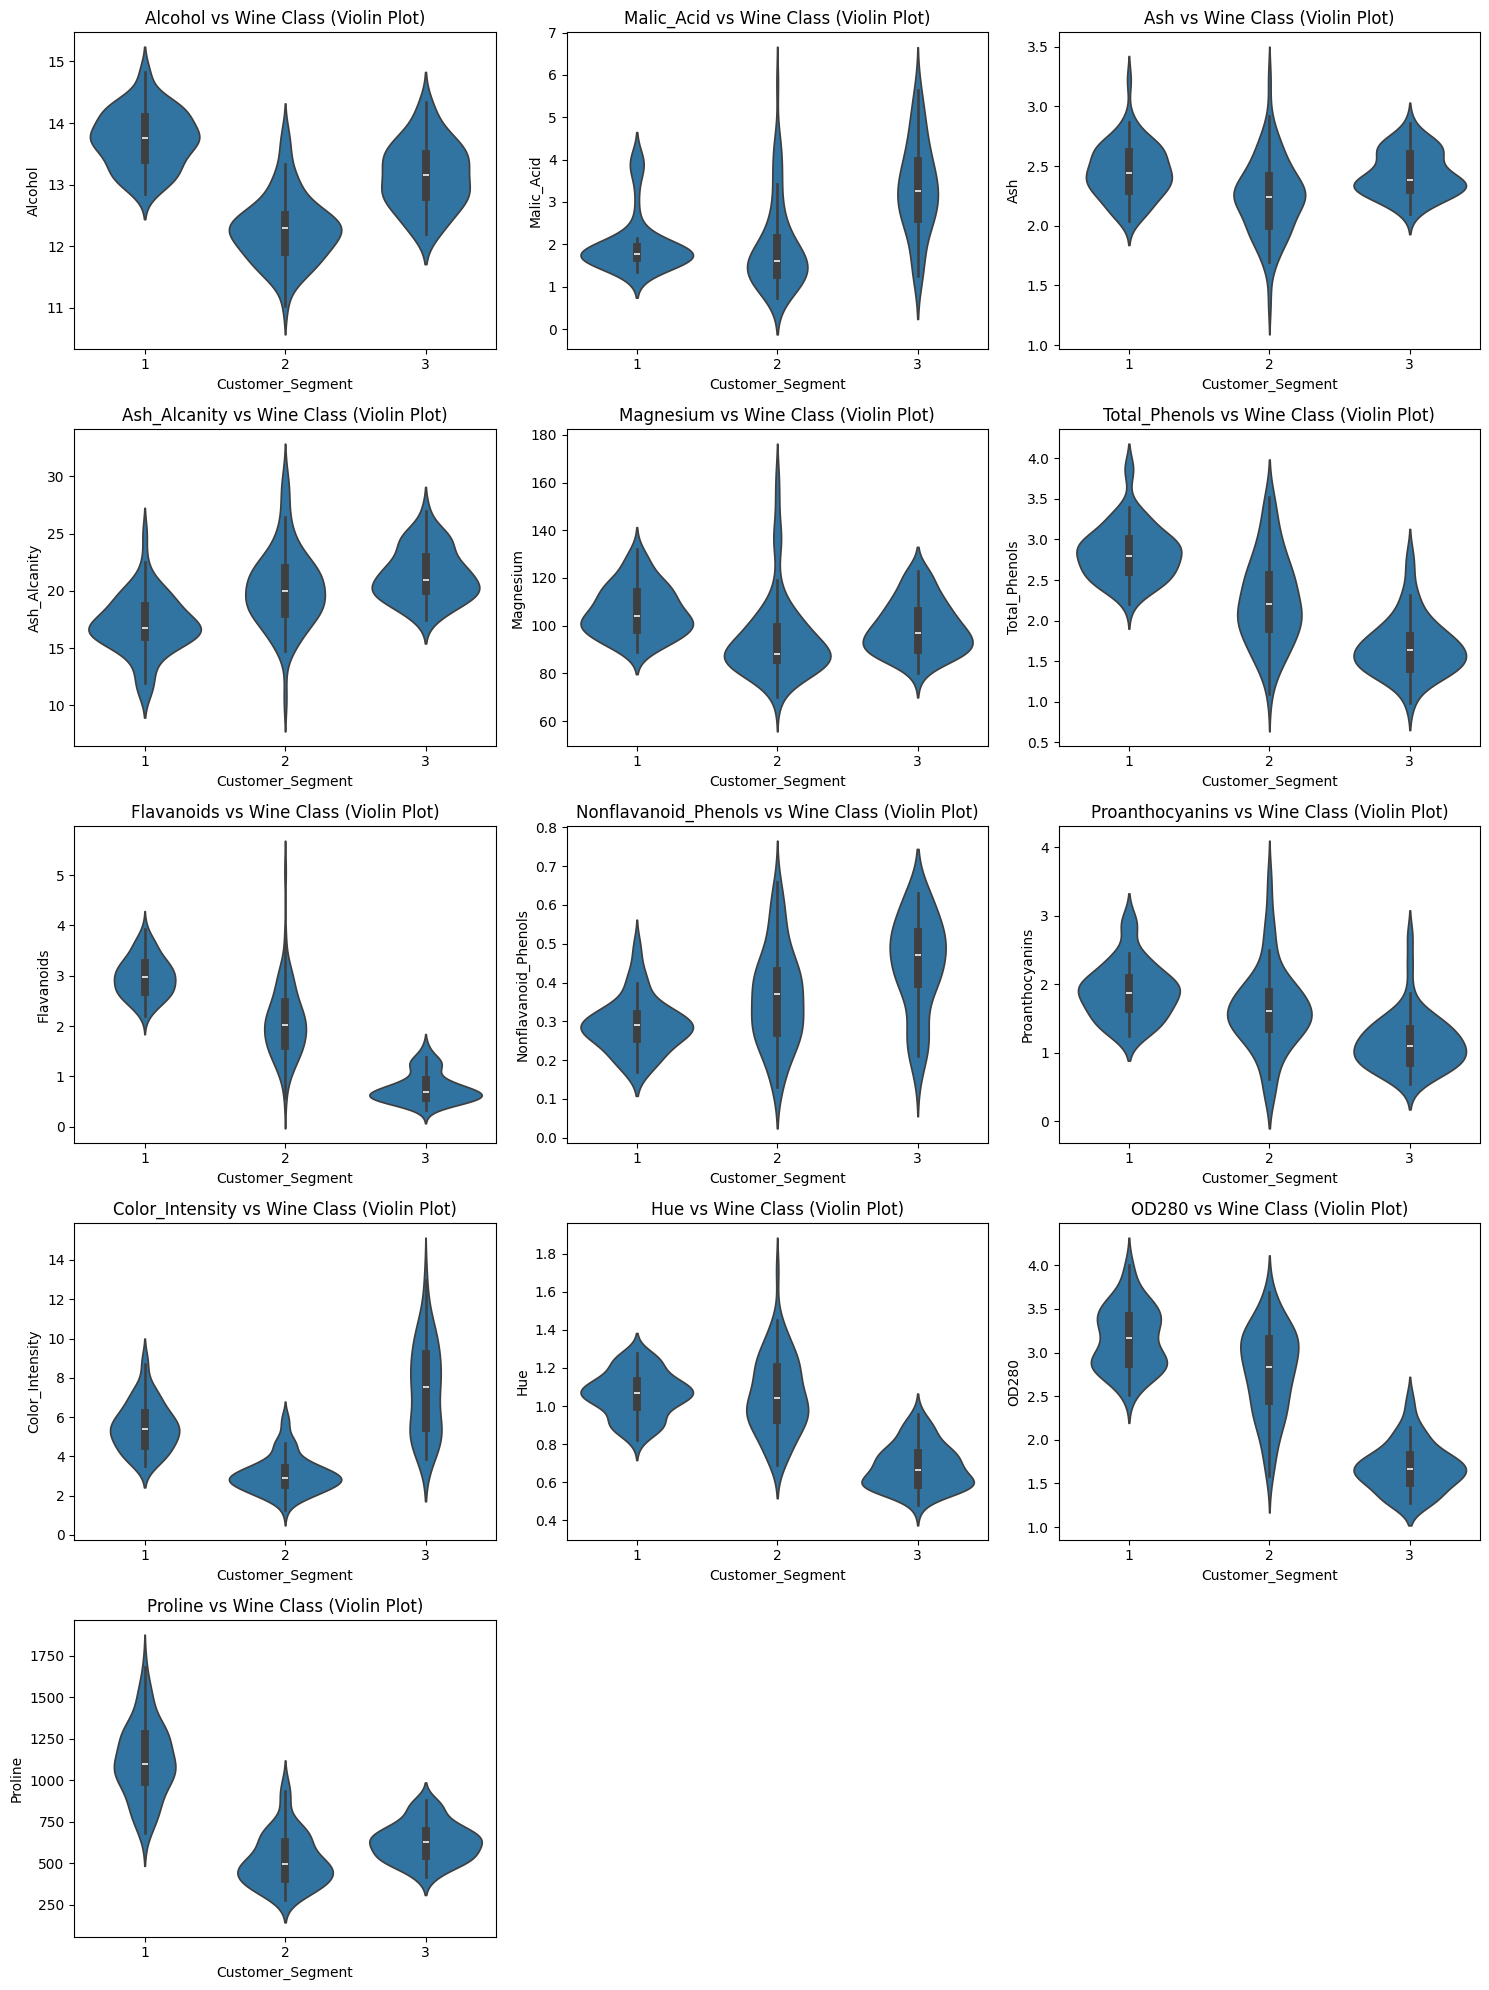

In [84]:
# Define the list of feature columns for analysis (re-using from previous cells)
feature_col = [
'Alcohol','Malic_Acid','Ash','Ash_Alcanity','Magnesium',
'Total_Phenols','Flavanoids','Nonflavanoid_Phenols',
'Proanthocyanins','Color_Intensity','Hue','OD280','Proline'
]

# The target variable (re-using from previous cells)
label = data["Customer_Segment"]

# Get the number of features for plotting
num_features_rel = len(feature_col)
# Define the number of columns for the grid layout
num_cols_rel = 3
# Calculate the number of rows needed for the grid (ceiling division)
num_rows_rel = (num_features_rel + num_cols_rel - 1) // num_cols_rel

# Create a figure with a size adjusted to fit all plots neatly
plt.figure(figsize=(num_cols_rel * 5, num_rows_rel * 4))

# Iterate through each feature to create a violin plot against the target variable
for i, col in enumerate(feature_col):
    plt.subplot(num_rows_rel, num_cols_rel, i + 1) # Create a subplot in the grid
    sns.violinplot(x=label, y=data[col]) # Generate a violin plot
    plt.title(f'{col} vs Wine Class (Violin Plot)') # Set the title for the subplot
    plt.xlabel('Customer_Segment') # Set the x-axis label
    plt.ylabel(col) # Set the y-axis label

# Adjust layout to prevent titles and labels from overlapping
plt.tight_layout()
plt.show()

## Decision Tree Classification

A Decision Tree recursively splits data using feature conditions.

Two popular split criteria:

### Entropy

Measures uncertainty:

Entropy = -Σ p log2(p)

### Gini Index

Measures impurity:

Gini = 1 - Σ p²

### Feature Seperation and Train Test Split

In [85]:
X = data[feature_col]
y = data["Customer_Segment"]

x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Classification Evaluation

Metrics:

Accuracy:
Percentage of correct predictions.

Precision:
Correct positive predictions.

Recall:
Ability to identify actual classes.

F1-score:
Balance between precision and recall.

#### Entropy Based Decision Tree

Entropy selects splits using information gain.

A split is preferred when it produces purer child nodes.

In [86]:
# Entropy
entropy_tree = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42,
    max_depth=5
)

entropy_tree.fit(x_train, y_train)

y_pred = entropy_tree.predict(x_test)

In [87]:
print("Accuracy:", accuracy_score(y_test,y_pred))

print("\nClassification Report:")
print(classification_report(y_test,y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test,y_pred))

Accuracy: 0.9722222222222222

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       0.93      1.00      0.97        14
           3       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36


Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]


##### Decision Tree Visualization

This shows:
- Selected feature
- Threshold value
- Samples
- Predicted class

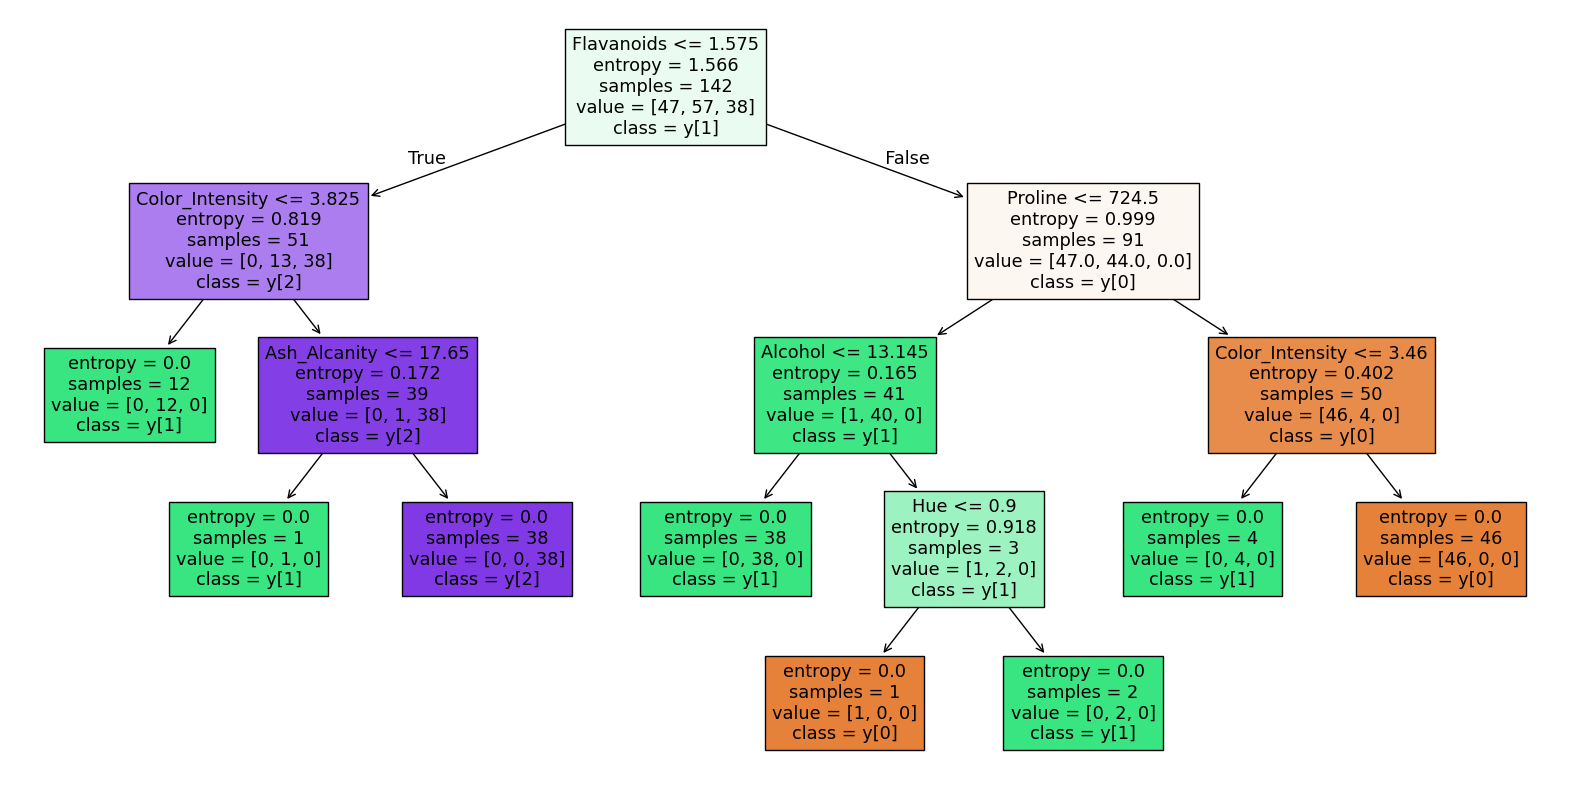

In [88]:
plt.figure(figsize=(20,10))
plot_tree(
    entropy_tree,
    feature_names=feature_col,
    class_names=True,
    filled=True
)
plt.show()

##### Feature Importance Analysis

Decision trees calculate how much each feature contributes to reducing impurity.

Higher importance means the feature was more useful for classification.

In [89]:
importance = pd.DataFrame({
    "Feature": feature_col,
    "Importance": entropy_tree.feature_importances_
})

importance.sort_values(
    by="Importance",
    ascending=False
)

,Feature,Importance
6,Flavanoids,0.403086
12,Proline,0.288063
9,Color_Intensity,0.248159
3,Ash_Alcanity,0.030182
0,Alcohol,0.018118
10,Hue,0.012393
4,Magnesium,0.000000
1,Malic_Acid,0.000000
2,Ash,0.000000
8,Proanthocyanins,0.000000


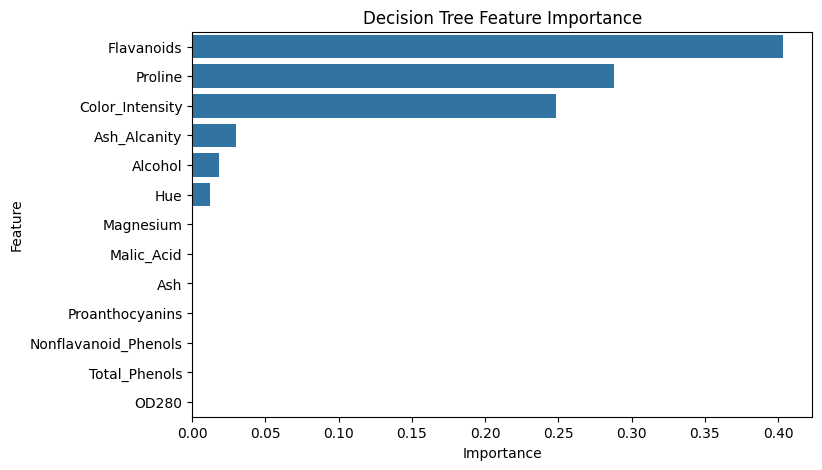

In [90]:
plt.figure(figsize=(8,5))
sns.barplot(
    data=importance.sort_values(
        by="Importance",
        ascending=False
    ),
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.show()

#### Gini-index Based Decission Tree

--- Gini-based Decision Tree ---
Accuracy (Gini): 0.9444444444444444

Classification Report (Gini):
              precision    recall  f1-score   support

           1       1.00      0.92      0.96        12
           2       0.88      1.00      0.93        14
           3       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36


Confusion Matrix (Gini):
[[11  1  0]
 [ 0 14  0]
 [ 0  1  9]]


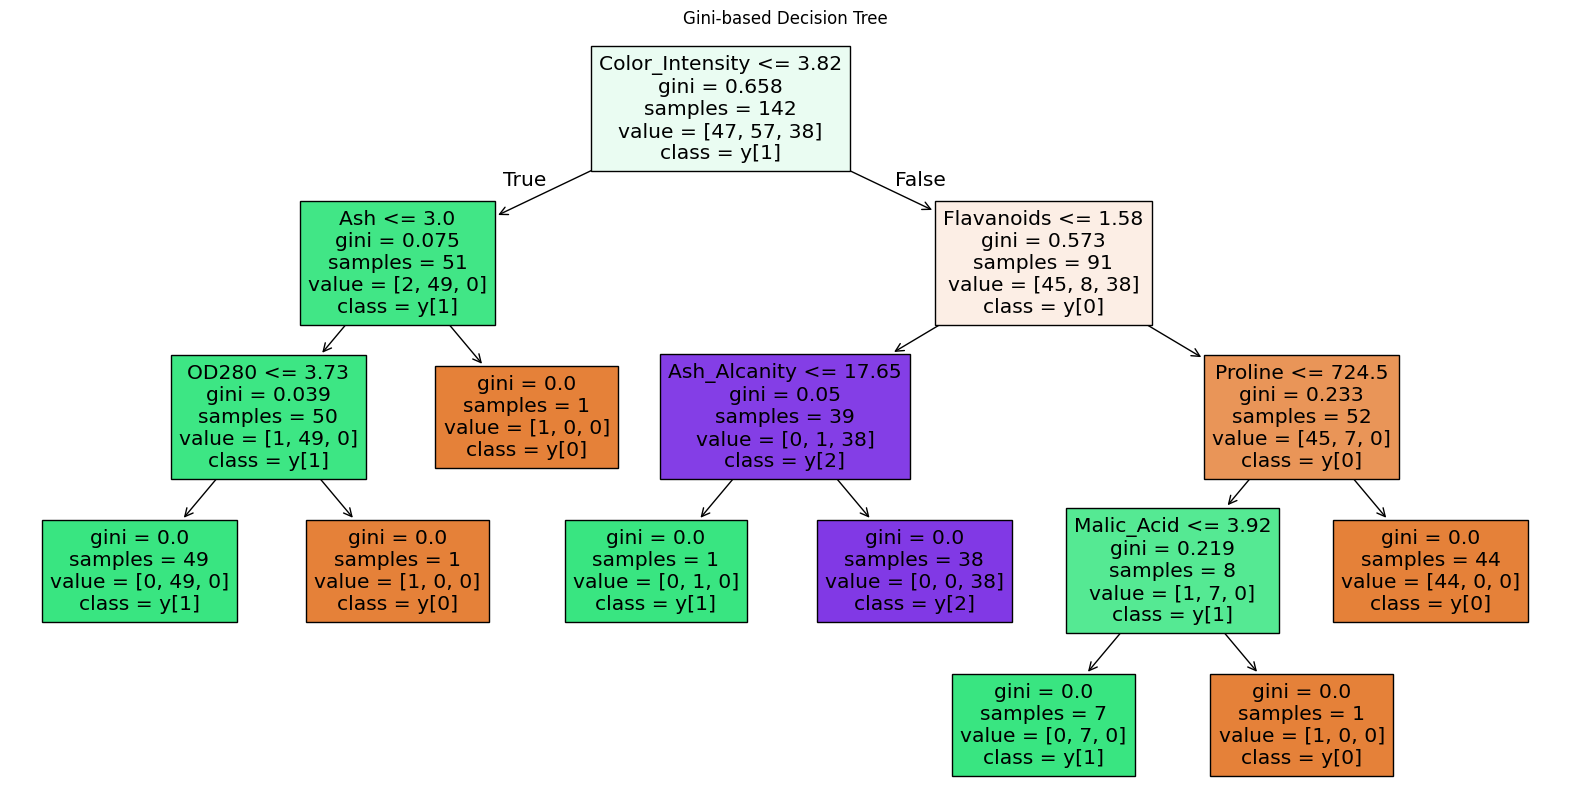


Feature Importance (Gini Tree):
                 Feature  Importance
6             Flavanoids    0.408073
9        Color_Intensity    0.400189
12               Proline    0.110985
11                 OD280    0.020986
3           Ash_Alcanity    0.020865
2                    Ash    0.020163
1             Malic_Acid    0.018738
4              Magnesium    0.000000
0                Alcohol    0.000000
8        Proanthocyanins    0.000000
7   Nonflavanoid_Phenols    0.000000
5          Total_Phenols    0.000000
10                   Hue    0.000000


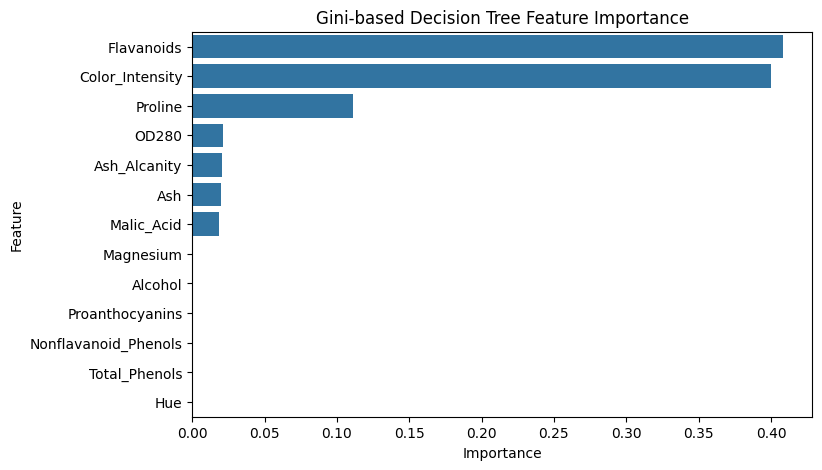

In [91]:
# Gini-based Decision Tree (CART algorithm uses Gini impurity by default for classification)
print("--- Gini-based Decision Tree ---")
gini_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
    max_depth=5
)

gini_tree.fit(x_train, y_train)

y_pred_gini = gini_tree.predict(x_test)

print("Accuracy (Gini):", accuracy_score(y_test, y_pred_gini))

print("\nClassification Report (Gini):")
print(classification_report(y_test, y_pred_gini))

print("\nConfusion Matrix (Gini):")
print(confusion_matrix(y_test, y_pred_gini))

# Visualize the Gini-based Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(
    gini_tree,
    feature_names=feature_col,
    class_names=True,
    filled=True
)
plt.title("Gini-based Decision Tree")
plt.show()

# Feature Importance for Gini-based Tree
importance_gini = pd.DataFrame({
    "Feature": feature_col,
    "Importance": gini_tree.feature_importances_
})

print("\nFeature Importance (Gini Tree):")
print(importance_gini.sort_values(by="Importance", ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=importance_gini.sort_values(
        by="Importance",
        ascending=False
    ),
    x="Importance",
    y="Feature"
)
plt.title("Gini-based Decision Tree Feature Importance")
plt.show()

## Some other Decission Tree Algorithms

- Advanced Decision Tree & Ensemble AlgorithmsID3 (Iterative Dichotomiser 3)
- C4.5 (Successor to ID3)
- C5.0 (Commercial upgrade of C4.5)
- CART (Classification and Regression Trees)
- CHAID (Chi-square Automatic Interaction Detection)
- MARS (Multivariate Adaptive Regression Splines)
- CTree (Conditional Inference Trees)
- QUEST (Quick, Unbiased, Efficient Statistical Tree)
- M5 (Model Trees)


In [92]:
# To be implemented at home

## Decision Tree Regression

Regression predicts continuous values.

Example:
House price prediction

The tree minimizes prediction error using criteria such as Mean Squared Error (MSE).

### Loading House Pricing Dataset (California Housing)

In [93]:
print("### Loading House Pricing Dataset (California Housing) ###")
# Load the California Housing dataset
housing = fetch_california_housing(as_frame=True)
data_reg = housing.frame
data_reg['MedHouseVal'] = housing.target # Add the target to the dataframe for easier EDA

print("Dataset loaded successfully.")
print(f"Shape of the dataset: {data_reg.shape}")
print("\nFirst 5 rows of the dataset:")
print(data_reg.head())

### Loading House Pricing Dataset (California Housing) ###
Dataset loaded successfully.
Shape of the dataset: (20640, 9)

First 5 rows of the dataset:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


### Exploratory Data Analysis (EDA)

In [94]:
print("\n### Exploratory Data Analysis (EDA) ###")
print("\nDataset Info:")
data_reg.info()

print("\nMissing Values:")
print(data_reg.isnull().sum())

print("\nStatistical Summary:")
print(data_reg.describe().T)


### Exploratory Data Analysis (EDA) ###

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Statistical Summary:
               count         mean          std         min         25%  \
MedInc       20640.0     3.870671     1.899822    0.499

### Visualizing Feature Distributions:


Visualizing Feature Distributions:


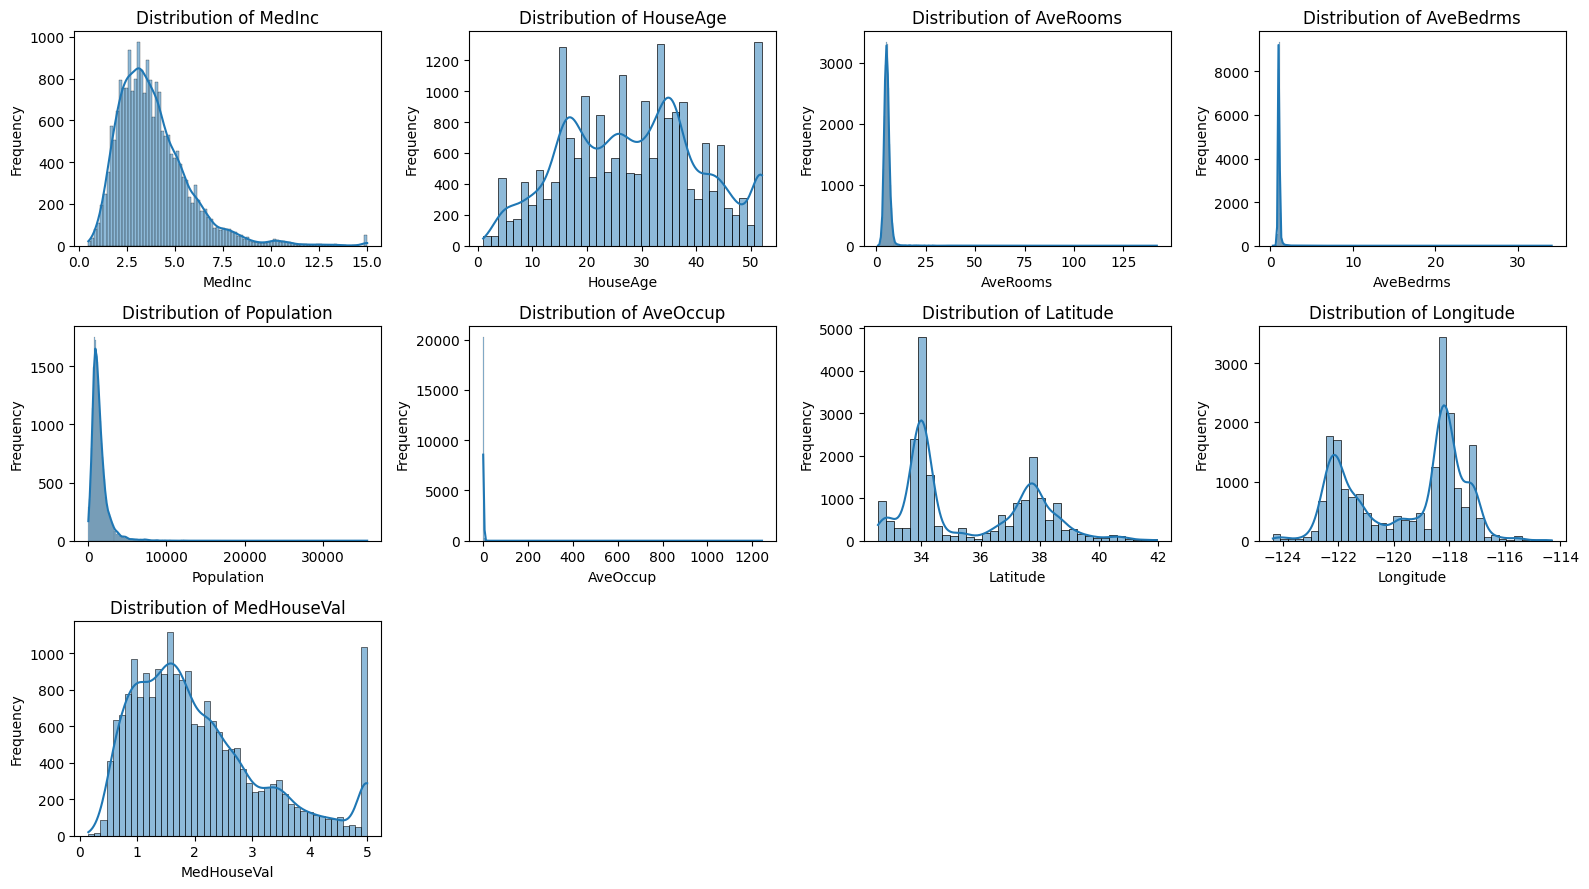

In [95]:
# Visualize distributions of features and target
print("\nVisualizing Feature Distributions:")
num_features_reg = data_reg.shape[1]
num_cols_reg = 4
num_rows_reg = (num_features_reg + num_cols_reg - 1) // num_cols_reg

plt.figure(figsize=(num_cols_reg * 4, num_rows_reg * 3))
for i, col in enumerate(data_reg.columns):
    plt.subplot(num_rows_reg, num_cols_reg, i + 1)
    sns.histplot(data_reg[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Correlation Matrix:


Correlation Matrix:


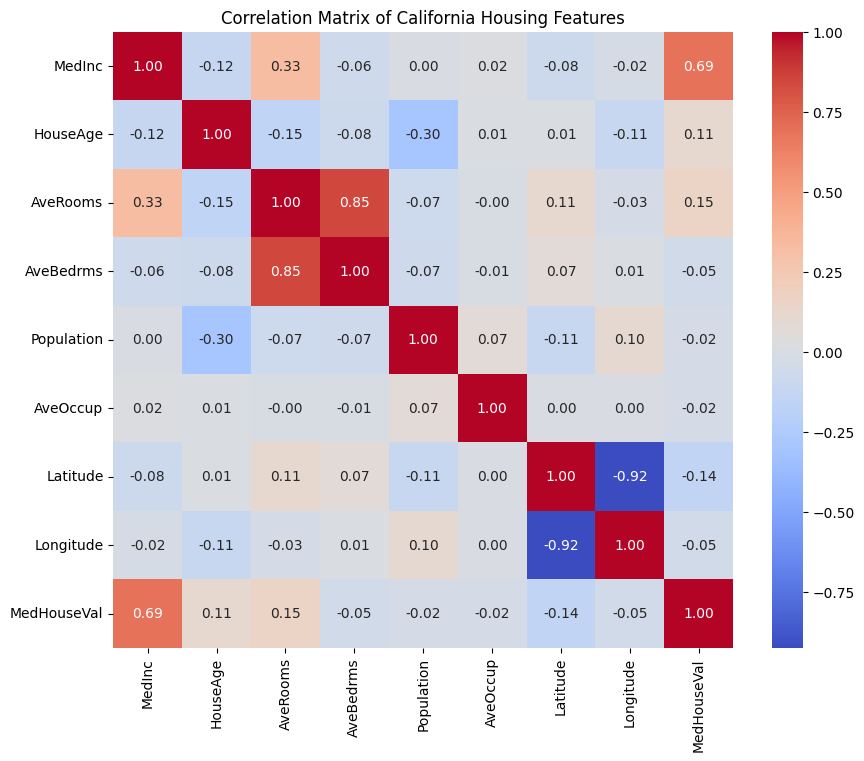


### Decision Tree Regression ###


In [96]:
# Correlation Matrix
print("\nCorrelation Matrix:")
plt.figure(figsize=(10, 8))
sns.heatmap(data_reg.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of California Housing Features')
plt.show()

print("\n### Decision Tree Regression ###")

### Geographical Distribution of Median House Value


--- Geographical Distribution of Median House Value ---


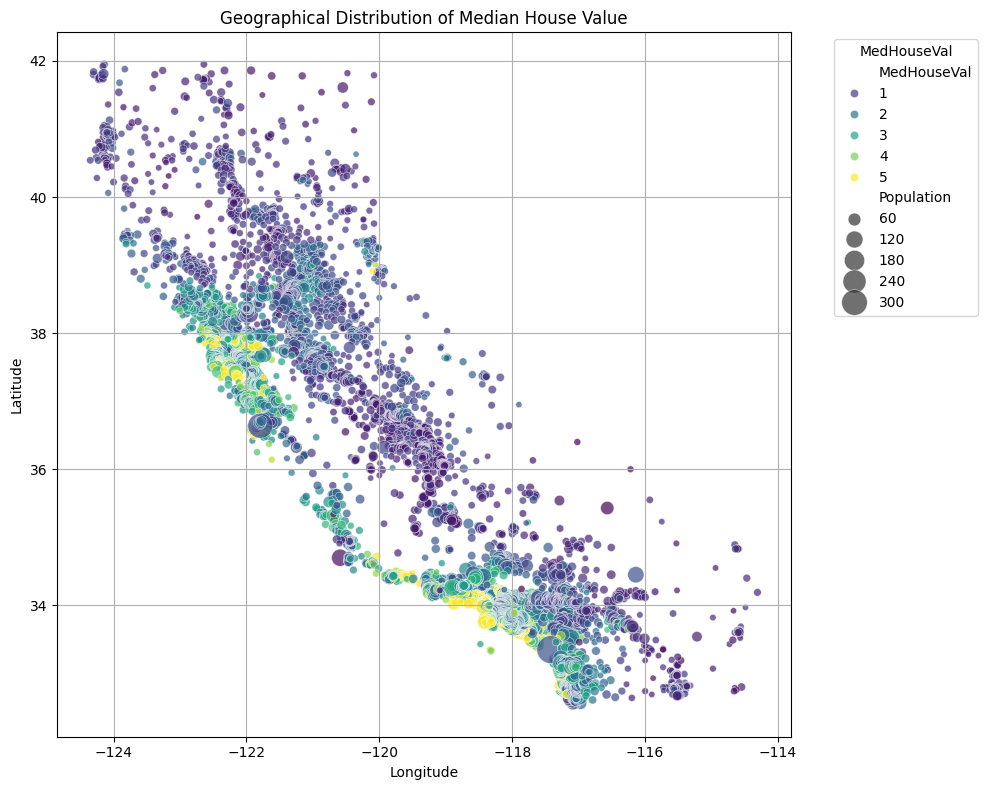

In [97]:
print("\n--- Geographical Distribution of Median House Value ---")

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=data_reg['Longitude'],
    y=data_reg['Latitude'],
    hue=data_reg['MedHouseVal'],
    palette='viridis',
    size=data_reg['Population']/100, # Use population for size variation
    sizes=(20, 400), # Range of marker sizes
    alpha=0.7
)
plt.title('Geographical Distribution of Median House Value')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.legend(title='MedHouseVal', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


--- Scatter Plots of Key Features vs. Median House Value ---


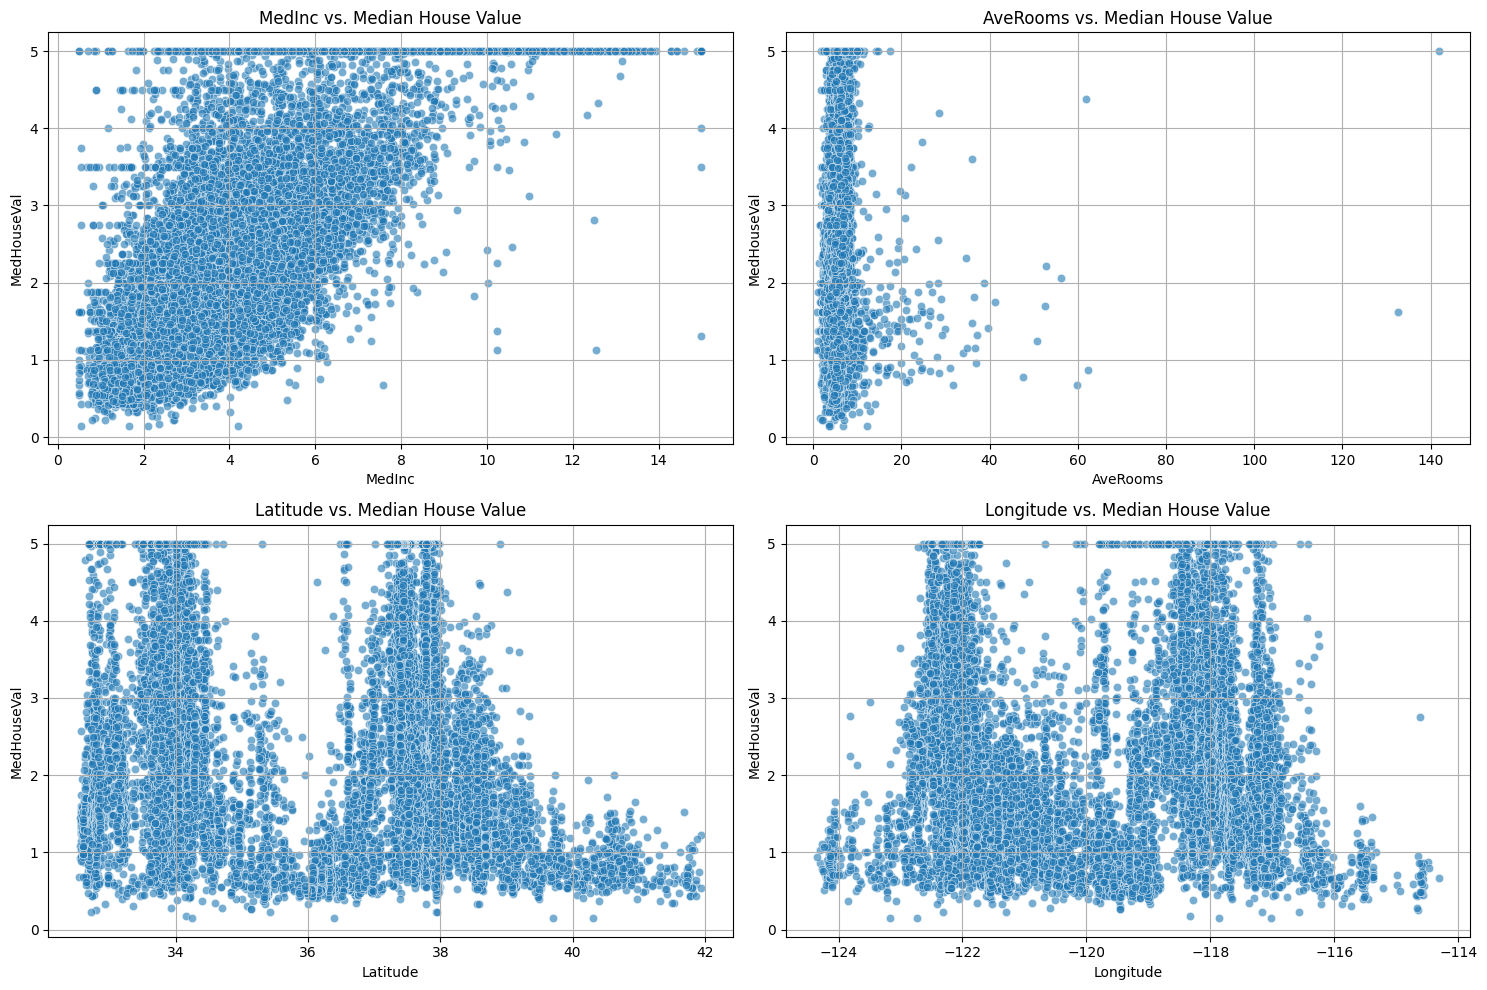

In [98]:
print("\n--- Scatter Plots of Key Features vs. Median House Value ---")

# Identify features that showed high correlation with MedHouseVal from the correlation matrix
high_corr_features = ['MedInc', 'AveRooms', 'Latitude', 'Longitude']

plt.figure(figsize=(15, 10))
for i, col in enumerate(high_corr_features):
    plt.subplot(2, 2, i + 1)
    sns.scatterplot(x=data_reg[col], y=data_reg['MedHouseVal'], alpha=0.6)
    plt.title(f'{col} vs. Median House Value')
    plt.xlabel(col)
    plt.ylabel('MedHouseVal')
    plt.grid(True)
plt.tight_layout()
plt.show()

### Define features (X) and target (y)

In [99]:
# Define features (X) and target (y)
X_reg = data_reg.drop('MedHouseVal', axis=1)
y_reg = data_reg['MedHouseVal']

# Split the data into training and testing sets
x_train_reg, x_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

print(f"Training set shape: {x_train_reg.shape}, {y_train_reg.shape}")
print(f"Testing set shape: {x_test_reg.shape}, {y_test_reg.shape}")

Training set shape: (16512, 8), (16512,)
Testing set shape: (4128, 8), (4128,)


### Initialize and train a Decision Tree Regressor


In [100]:
# You can adjust max_depth to control overfitting
reg_tree = DecisionTreeRegressor(random_state=42, max_depth=7)
print(f"Training Decision Tree Regressor with max_depth={reg_tree.max_depth}...")
reg_tree.fit(x_train_reg, y_train_reg)

Training Decision Tree Regressor with max_depth=7...


DecisionTreeRegressor(max_depth=7, random_state=42)

### Make predictions on the test set

In [101]:
# Make predictions on the test set
y_pred_reg = reg_tree.predict(x_test_reg)

# Evaluate the regression model
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("\n--- Regression Model Evaluation ---")
print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Mean Squared Error (MSE): {mse:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R-squared (R2): {r2:.3f}")


--- Regression Model Evaluation ---
Mean Absolute Error (MAE): 0.473
Mean Squared Error (MSE): 0.457
Root Mean Squared Error (RMSE): 0.676
R-squared (R2): 0.652


### Visualize a portion of the Decision Tree Regressor (can be very large for deep trees)


Visualizing the Decision Tree Regressor (first few levels):


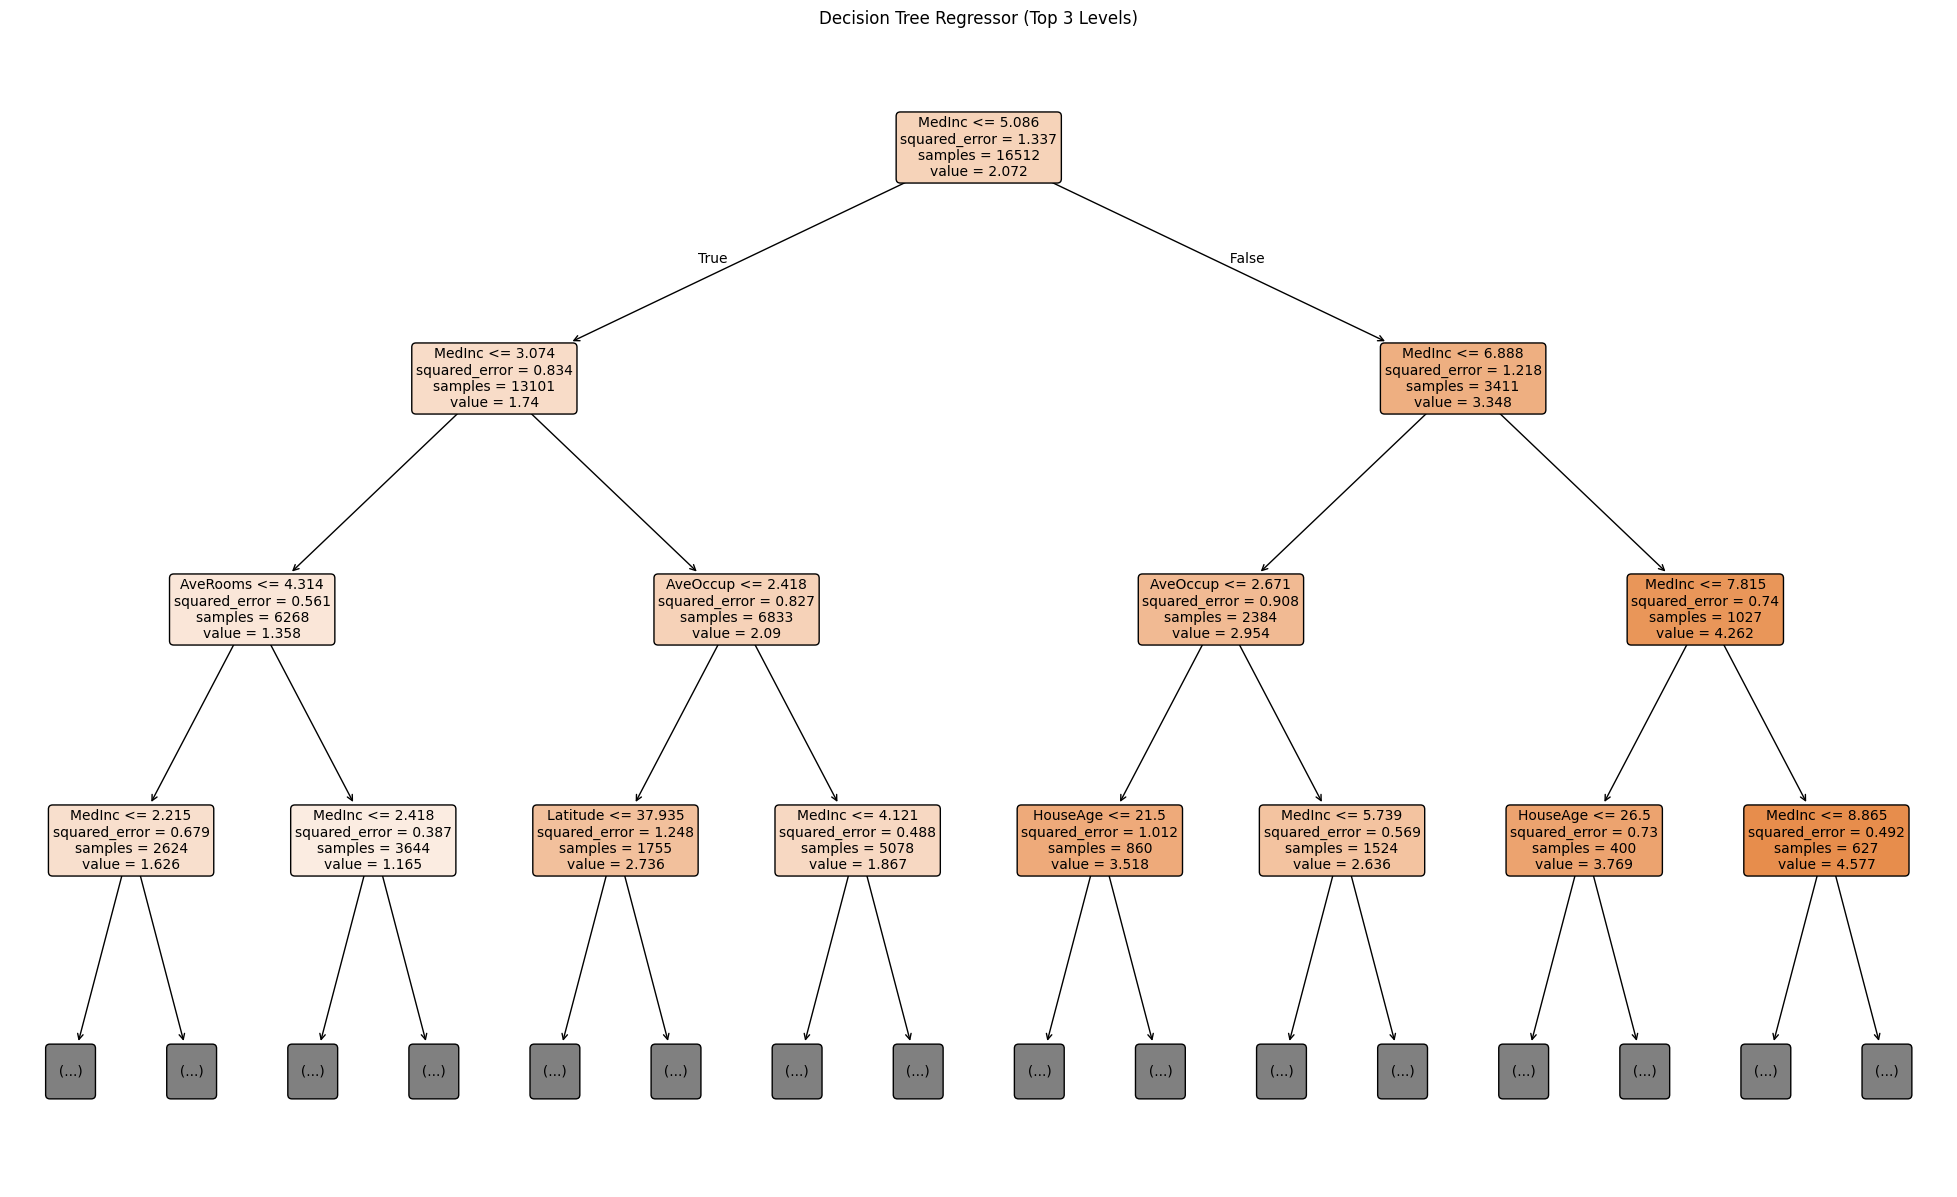

In [102]:
# Visualize a portion of the Decision Tree Regressor (can be very large for deep trees)
print("\nVisualizing the Decision Tree Regressor (first few levels):")
plt.figure(figsize=(25, 15))
plot_tree(
    reg_tree,
    feature_names=X_reg.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3 # Visualize only the top 3 levels for clarity
)
plt.title("Decision Tree Regressor (Top 3 Levels)")
plt.show()

### Plot actual vs predicted values


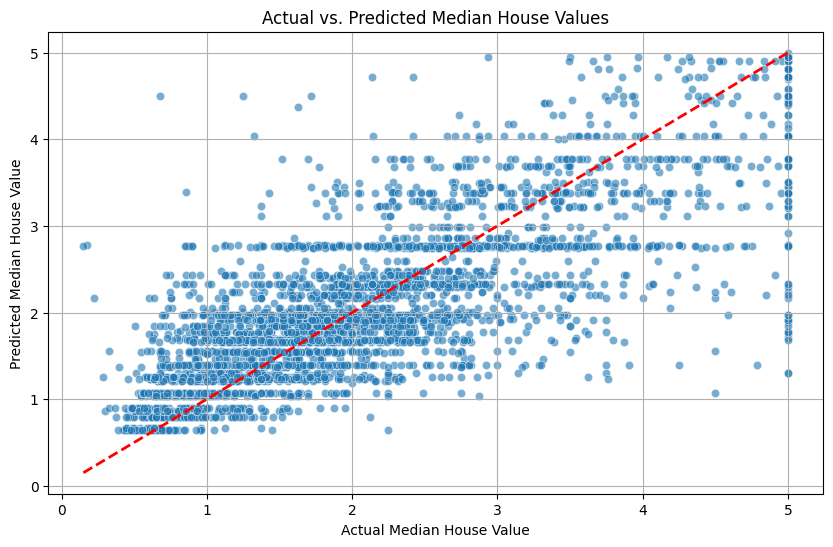

In [103]:
# Plot actual vs predicted values
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test_reg, y=y_pred_reg, alpha=0.6)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], '--r', linewidth=2)
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Actual vs. Predicted Median House Values")
plt.grid(True)
plt.show()

### External Links and References

Here are some additional resources related to Decision Trees and the Wine dataset:

*   **Scikit-learn Decision Tree Documentation**: [https://scikit-learn.org/stable/modules/tree.html](https://scikit-learn.org/stable/modules/tree.html)
*   **UCI Machine Learning Repository - Wine Dataset**: [https://archive.ics.uci.edu/ml/datasets/Wine](https://archive.ics.uci.edu/ml/datasets/Wine)

### Further Exploration

You can explore further topics like:

*   **Ensemble Methods**: Random Forests and Gradient Boosting for improved performance.
*   **Hyperparameter Tuning**: Techniques to optimize Decision Tree parameters (e.g., GridSearchCV, RandomizedSearchCV).
*   **Pruning Decision Trees**: Methods to prevent overfitting in Decision Trees.

# Support Vector Machine (SVM)

A **Support Vector Machine (SVM)** is a supervised machine learning algorithm that can be used for:

- **Classification** (most common application)
- **Regression** (Support Vector Regression, SVR)
- **Outlier/Novelty Detection** (One-Class SVM)

The primary objective of an SVM is to find the **optimal decision boundary (hyperplane)** that best separates data points belonging to different classes.

## Linear SVM

For linearly separable data, an SVM finds the hyperplane that **maximizes the margin**, i.e., the distance between the decision boundary and the nearest training samples from each class.

<div align="center">

Decision Boundary: $w^Tx + b = 0$

Margin Width: $\frac{2}{\|w\|}$

</div>

Unlike many classifiers that simply separate the classes, SVM chooses the separator with the **largest possible margin**, which often leads to better generalization on unseen data.

### Why Maximize the Margin?

A larger margin provides a "safety buffer" between classes, making the classifier:

- More robust to noise and small perturbations in the data.
- Less sensitive to minor changes in training samples.
- Better at generalizing to unseen data.

## Support Vectors

The **support vectors** are the training samples that lie closest to the decision boundary. These points are the most informative because they determine the position and orientation of the optimal hyperplane.

Key observations:

- Only the support vectors influence the decision boundary.
- Removing non-support vectors usually has little or no effect on the classifier.
- Removing a support vector can significantly change the learned decision boundary.

## Soft-Margin SVM

Real-world datasets are rarely perfectly separable. Soft-margin SVM introduces a regularization parameter **C** that allows some training points to violate the margin in order to achieve better generalization.

- **Small C:** Wider margin, more tolerance for misclassification (lower variance, higher bias).
- **Large C:** Narrower margin, fewer training errors (higher variance, increased risk of overfitting).

## Nonlinear SVM and the Kernel Trick

Many datasets cannot be separated using a straight line or hyperplane. SVM addresses this by using **kernel functions**, which implicitly transform the data into a higher-dimensional feature space where linear separation becomes possible.

Commonly used kernels include:

- **Linear Kernel:** Suitable for linearly separable or high-dimensional sparse data.
- **Polynomial Kernel:** Captures polynomial relationships between features.
- **Radial Basis Function (RBF) Kernel:** The most widely used kernel for modeling complex nonlinear decision boundaries.

> **Note:** The kernel transformation is performed **implicitly**, meaning the higher-dimensional features are never computed explicitly. This technique is known as the **Kernel Trick**, allowing SVMs to efficiently learn nonlinear decision boundaries.

---

## Topics Covered

We will explore:

1. Linear SVM and the concept of maximum margin.
2. Decision boundaries and support vectors.
3. Effect of the training dataset size.
4. Soft-margin SVM and the role of **C**.
5. Nonlinear classification using kernel functions.
6. Explicit quadratic feature transformation vs. the Kernel Trick.
7. Polynomial and RBF kernels.
8. Effect of the **gamma ($\gamma$)** parameter in the RBF kernel.
9. SVM classification on the UCI Wine dataset.
10. PCA-based visualization of high-dimensional data.
11. Hyperparameter tuning using **GridSearchCV**.

In [104]:
from sklearn.datasets import make_blobs, make_circles
from sklearn.svm import SVC

import plotly.graph_objects as go
from plotly.subplots import make_subplots

## Utility function

In [105]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    x = np.linspace(xlim[0], xlim[1], 300)
    y = np.linspace(ylim[0], ylim[1], 300)

    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T

    P = model.decision_function(xy).reshape(X.shape)

    ax.contourf(X, Y, P > 0, alpha=0.2)
    ax.contour(
        X,
        Y,
        P,
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"],
        linewidths=[1, 2, 1]
    )

    if plot_support:
        ax.scatter(
            model.support_vectors_[:,0],
            model.support_vectors_[:,1],
            s=180,
            facecolors="none",
            edgecolors="black",
            linewidth=2,
            label="Support Vectors"
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## 1. Linear separable data

We train a Support Vector Classifier (`SVC`) with a linear kernel on our synthetic dataset. The plot will show the optimal hyperplane (decision boundary) and the margins, emphasizing the support vectors.

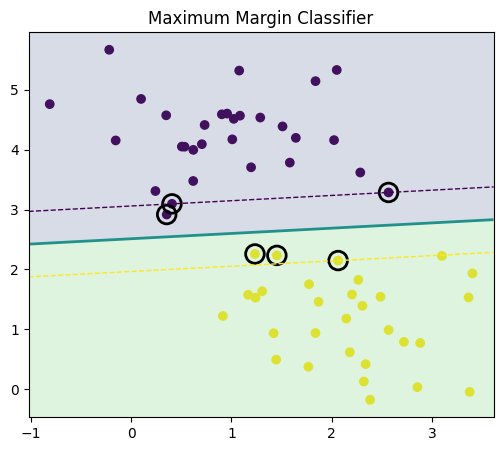

Support vectors: 6
Training Accuracy: 1.0


In [106]:
X, y = make_blobs(
    n_samples=60,
    centers=2,
    cluster_std=0.7,
    random_state=0
)

model = SVC(kernel='linear', C=1)
model.fit(X, y)

plt.figure(figsize=(6,5))
plt.scatter(X[:,0], X[:,1], c=y)
plot_svc_decision_function(model)
plt.title("Maximum Margin Classifier")
plt.show()

print("Support vectors:", len(model.support_vectors_))
print("Training Accuracy:", accuracy_score(y, model.predict(X)))

## 2. Only support vectors matter

Support vectors are the data points closest to the decision boundary that influence the position and orientation of the hyperplane. They are crucial for defining the SVM model.

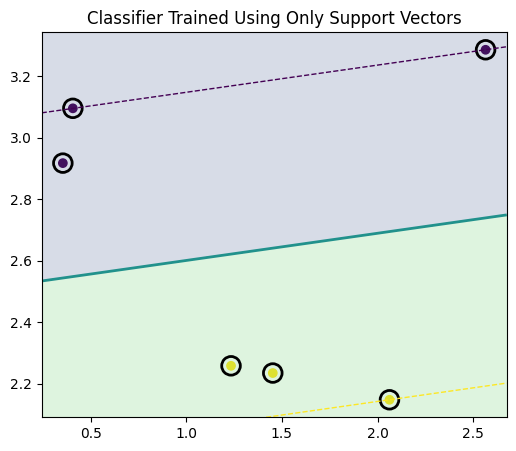

In [107]:
support = model.support_
X_sv = X[support]
y_sv = y[support]

model2 = SVC(kernel='linear')
model2.fit(X_sv, y_sv)

plt.figure(figsize=(6,5))
plt.scatter(X_sv[:,0], X_sv[:,1], c=y_sv)
plot_svc_decision_function(model2)
plt.title("Classifier Trained Using Only Support Vectors")
plt.show()

## 3. Effect of Training Size

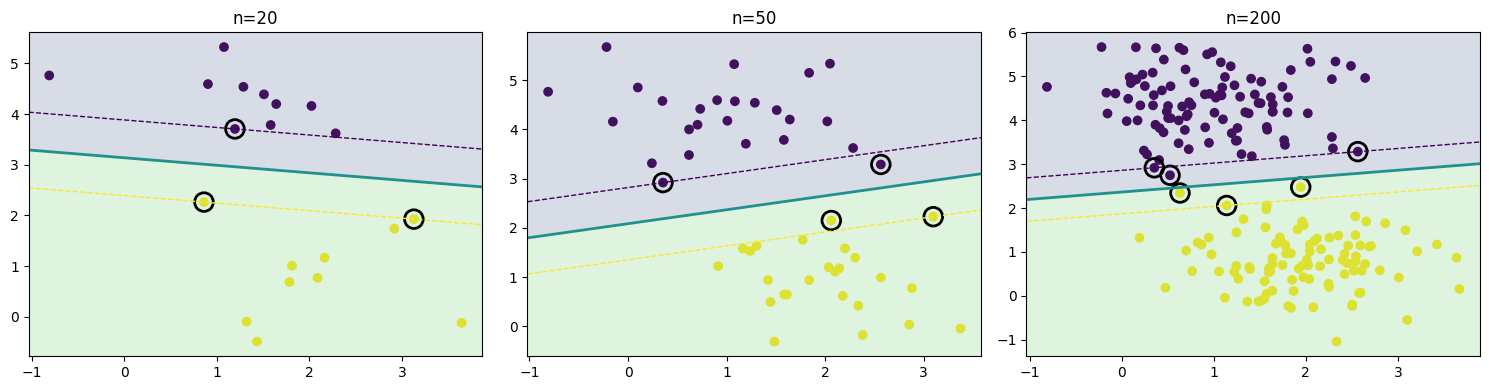

In [108]:
fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax, n in zip(axes, [20, 50, 200]):
    X, y = make_blobs(n_samples=n, centers=2, random_state=0, cluster_std=0.7)
    model = SVC(kernel='linear')
    model.fit(X,y)
    ax.scatter(X[:,0], X[:,1], c=y)
    plot_svc_decision_function(model, ax=ax)
    ax.set_title(f"n={n}")

plt.tight_layout()
plt.show()

## 4. Soft Margin (Effect of C)

Regularization Parameter `C` in SVM controls the trade-off between achieving a low training error and a large margin. A small `C` makes the margin wider, allowing more misclassifications (stronger regularization), while a large `C` makes the margin narrower and strives for perfect classification (weaker regularization, prone to overfitting).

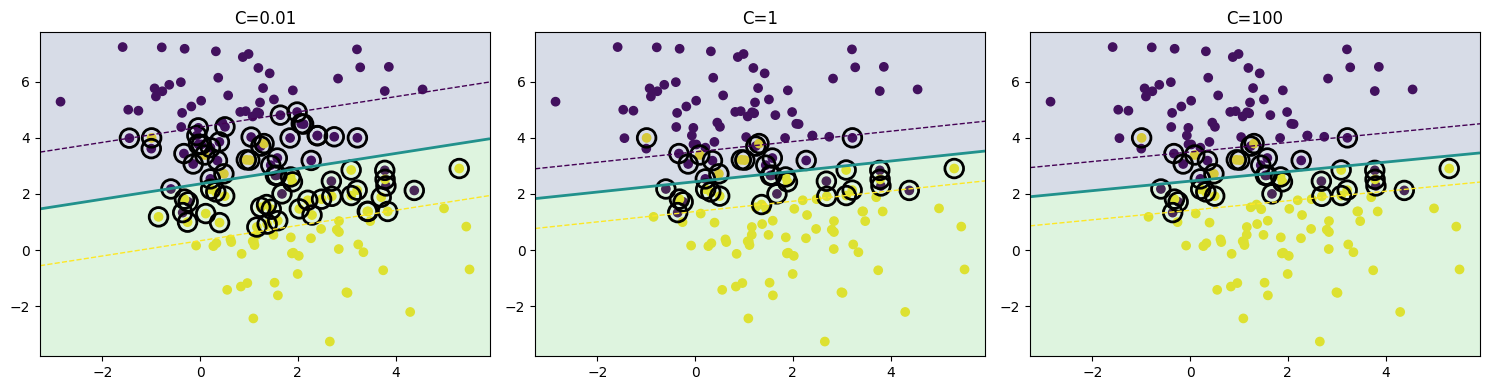

In [109]:
X, y = make_blobs(
    n_samples=150,
    centers=2,
    cluster_std=1.5,
    random_state=0
)

fig, axes = plt.subplots(1,3, figsize=(15,4))

for ax, C in zip(axes,[0.01,1,100]):
    model = SVC(kernel='linear', C=C)
    model.fit(X,y)
    ax.scatter(X[:,0], X[:,1], c=y)
    plot_svc_decision_function(model, ax=ax)
    ax.set_title(f"C={C}")

plt.tight_layout()
plt.show()

With a low `C` value, the SVM prioritizes a wider margin, even if it means some data points fall within the margin or are misclassified. This can lead to a more generalized model.

Conversely, a high `C` value pushes the SVM to minimize misclassifications, resulting in a narrower margin. This can lead to a model that fits the training data very closely but might not generalize well to unseen data (overfitting).

## 5. Nonlinear Data

When attempting to use a linear kernel on non-linearly separable data, the SVM fails to find an effective decision boundary, illustrating the need for kernel tricks.

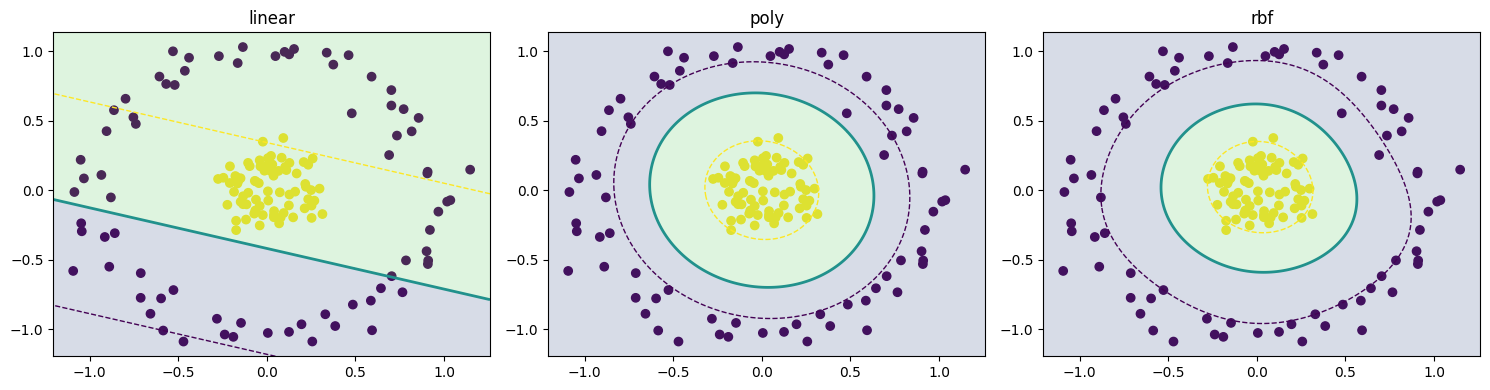

In [110]:
X, y = make_circles(
    n_samples=150,
    factor=0.2,
    noise=0.08,
    random_state=0
)

fig, axes = plt.subplots(1,3, figsize=(15,4))

for ax, kernel in zip(axes,["linear","poly","rbf"]):
    model = SVC(kernel=kernel, degree=2)
    model.fit(X,y)
    ax.scatter(X[:,0], X[:,1], c=y)
    plot_svc_decision_function(model, ax=ax, plot_support=False)
    ax.set_title(kernel)

plt.tight_layout()
plt.show()

When attempting to use a linear kernel on non-linearly separable data, the SVM fails to find an effective decision boundary, illustrating the need for kernel tricks.

RBF (Radial Basis Function) kernel is a common 'kernel trick' that allows SVMs to create non-linear decision boundaries by implicitly mapping the data into a higher-dimensional space.

Polynomial kernel transforms the data into a higher dimension to find a non-linear decision boundary. The `degree` parameter controls the complexity of this transformation.


## Quadratic vs. RBF Kernels

Both the **Quadratic (Polynomial Degree-2)** and **RBF** kernels enable SVMs to classify **nonlinearly separable** data by mapping it into a higher-dimensional feature space.
> **Key Difference:**  
> The **Quadratic kernel** maps data into a **finite-dimensional** polynomial feature space, whereas the **RBF kernel** implicitly maps data into an **infinite-dimensional** feature space, allowing it to model much more complex decision boundaries.
---

### Quadratic (Polynomial Degree-2) Kernel

A quadratic kernel performs an **implicit** mapping to a **finite-dimensional** feature space. For a two-dimensional input

$$
\mathbf{x} = (x_1, x_2),
$$

the corresponding feature transformation is

$$
\phi(\mathbf{x}) =
\left[
x_1,\;
x_2,\;
x_1^2,\;
\sqrt{2}\,x_1x_2,\;
x_2^2
\right].
$$

The kernel function is

$$
K(\mathbf{x}, \mathbf{z}) = (\mathbf{x}^\top \mathbf{z} + 1)^2.
$$

This transformation allows the SVM to learn **quadratic decision boundaries** (e.g., ellipses, parabolas, or hyperbolas) in the original feature space.

---

### RBF Kernel

The **Radial Basis Function (RBF)** kernel implicitly maps data into an **infinite-dimensional** feature space using

$$
K(\mathbf{x}, \mathbf{z}) =
\exp\left(-\gamma \|\mathbf{x}-\mathbf{z}\|^2\right).
$$

This enables the SVM to learn highly flexible nonlinear decision boundaries.

Since the infinite-dimensional mapping cannot be visualized directly, we use a simple **3D radial feature** such as

$$
z = x_1^2 + x_2^2
$$

or

$$
z = e^{-(x_1^2+x_2^2)}
$$

to build geometric intuition. **This is only an approximation** of the actual RBF feature mapping.

---

### Explicit vs. Implicit Feature Transformations

**Explicit quadratic feature transformation** manually add a new feature,

$$
z = x_1^2 + x_2^2.
$$

A **linear SVM** can then separate the transformed data using a plane in this three-dimensional space. This illustrates the idea behind a **Polynomial kernel**, which performs a finite-dimensional nonlinear transformation.

**Implicit feature transformation** compares the decision boundaries learned by a **Polynomial kernel** and an **RBF kernel** in the original two-dimensional space.

Although both kernels successfully classify the nonlinear data, they work differently:

- **Polynomial kernel:** Performs an implicit version of a finite-dimensional polynomial feature transformation.
- **RBF kernel:** Computes similarities using

  $$
  K(x,z)=\exp(-\gamma\|x-z\|^2),
  $$

  which is equivalent to an **implicit mapping into an infinite-dimensional feature space**.

Because the RBF feature space is infinite-dimensional, **its separating hyperplane cannot be visualized directly**. Instead, we visualize only the resulting nonlinear decision boundary in the original input space.

In [111]:
X, y = make_circles(n_samples=200, factor=0.3, noise=0.05, random_state=42)

# Explicit Feature Transformation: z = x1² + x2²
z = X[:, 0]**2 + X[:, 1]**2
X3 = np.column_stack((X, z))

model = SVC(kernel="linear")
model.fit(X3, y)

# Decision Plane
xx, yy = np.meshgrid(
    np.linspace(X3[:,0].min(), X3[:,0].max(), 50),
    np.linspace(X3[:,1].min(), X3[:,1].max(), 50))
w = model.coef_[0]
b = model.intercept_[0]
zz = -(w[0]*xx + w[1]*yy + b) / w[2]

# Split classes
mask0 = y == 0
mask1 = y == 1
support = model.support_vectors_

# Create figure with two panels
fig = make_subplots(rows=1, cols=2, specs=[[{"type": "xy"},{"type": "scene"}]], column_widths=[0.38, 0.62],subplot_titles=(
        "Original Nonlinear Data", "After Explicit Feature Transformation"))

# Original 2D Space
fig.add_trace(go.Scatter(x=X[mask0,0],y=X[mask0,1],mode="markers",marker=dict(color="royalblue",size=8),name="Class 0"),
    row=1,col=1)

fig.add_trace(go.Scatter(x=X[mask1,0],y=X[mask1,1],mode="markers",marker=dict(color="crimson",size=8),name="Class 1"),
    row=1,col=1)

fig.update_xaxes(title="x₁", row=1, col=1)
fig.update_yaxes(title="x₂", row=1, col=1)

#Transformed Space
fig.add_trace(go.Scatter3d(x=X3[mask0,0],y=X3[mask0,1],z=X3[mask0,2],mode="markers",
        marker=dict(size=5,color="royalblue",opacity=0.9),
        name="Class 0",showlegend=False),
    row=1,col=2)

fig.add_trace(go.Scatter3d(x=X3[mask1,0],y=X3[mask1,1],z=X3[mask1,2],mode="markers",
        marker=dict(size=5,color="crimson",opacity=0.9),
        name="Class 1",showlegend=False),
    row=1,col=2)

# Support Vectors
fig.add_trace(go.Scatter3d(x=support[:,0],y=support[:,1],z=support[:,2],mode="markers",
        marker=dict(size=9,color="gold",symbol="diamond",line=dict(color="black",width=2)),
        name="Support Vectors"),
    row=1,col=2)

# Decision Plane
fig.add_trace(go.Surface(x=xx,y=yy,z=zz,opacity=0.22,colorscale="Viridis",showscale=False,name="Decision Plane",
        contours=dict(z=dict(show=True,color="black",width=1))),
    row=1, col=2)

# Layout
fig.update_layout(
    title=dict(text="<b>From Nonlinear to Linear: Explicit Feature Transformation</b>",x=0.5,font=dict(size=24)),
    template="plotly_white", width=1200, height=700,
    legend=dict(x=0.86,y=0.95,bgcolor="rgba(255,255,255,0.85)",bordercolor="lightgray",borderwidth=1),
    margin=dict(l=10,r=10,b=10,t=70),
    scene=dict(
        xaxis=dict(title="x₁",showbackground=False,gridcolor="lightgray"),
        yaxis=dict(title="x₂",showbackground=False,gridcolor="lightgray"),
        zaxis=dict(title="x₁² + x₂²",showbackground=False,gridcolor="lightgray"),
        aspectmode="cube",camera=dict(eye=dict(x=2.0,y=-1.8,z=1.4))))

# Annotations
fig.add_annotation(
    text="<b>Feature Transformation</b><br>(x₁,x₂) → (x₁,x₂,x₁²+x₂²)",x=0.72,y=0.94,xref="paper",yref="paper",
    showarrow=False,bgcolor="rgba(255,255,255,0.90)",bordercolor="gray")
fig.add_annotation(text="<b>Decision Plane</b><br>w₁x₁ + w₂x₂ + w₃z + b = 0",x=0.98,y=0.08,xref="paper",yref="paper",xanchor="right",
    showarrow=False,bgcolor="rgba(255,255,255,0.90)",bordercolor="gray")

fig.show()